# Figuras de la validación de la metodología (Cap 3_4)

Tanda **`artefactos/barrido/sec-0-2-9-10 severo`**: 12 medidas individuales y sus combinaciones sobre los 10 escenarios de mayor ENS del caso base.

El notebook **solo lee** artefactos ya calculados y exporta a `Tesis_Francisca_Muñoz_M/Figuras/Resultados/`. Para cambiar el aspecto de las figuras basta con editar la celda de estilo y volver a correr todo.

| figura | salida |
|---|---|
| Curvas de abatimiento de las medidas individuales | `mac ENS.png`, `mac SAIDI.png`, `mac SAIFI.png` |
| ENS por zona, caso base y cartera completa | `ens_zona_base_cartera.pdf` |
| ENS por escenario, caso base y cartera completa | `ens_pareada_escenarios.pdf` |
| Figuras de Lebú (copia desde `figuras_lebu/`) | `lebu_*.pdf` |
| Planes de la matriz plan × escenario, costo anual y reducción | `planes_costo_reduccion_ens/_saidi/_saifi.pdf` |

In [4]:
from pathlib import Path
import json, shutil

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

APP = Path.cwd()                                   # .../abc/mi_proyecto/app/app
TANDA = APP / 'artefactos'  / 'validacion' / 'barrido' / 'sec-0-2-9-10 severo'
SEVERO = APP / 'figuras_presentacion_severo'       # resumen ya validado de la tanda
TESIS = APP.parents[3] / 'Tesis_Francisca_Muñoz_M' / 'Figuras' / 'Resultados'
TESIS.mkdir(parents=True, exist_ok=True)

ESPERADOS = pd.read_csv(SEVERO / 'indicadores_esperados.csv')
MUESTRA = json.loads((SEVERO / 'muestra.json').read_text(encoding='utf-8'))
ESCENARIOS = MUESTRA['escenarios_internos']
CARTERA = MUESTRA['cartera_referencia']            # las 12 medidas juntas
assert len(ESCENARIOS) == 10 and CARTERA.startswith('combo_')
print('Escenarios', ESCENARIOS)
print('Salida', TESIS)

Escenarios [1, 9, 15, 21, 41, 57, 78, 82, 93, 98]
Salida c:\Users\usuario\erad\Tesis_Francisca_Muñoz_M\Figuras\Resultados


In [6]:
# ── Estilo común (editar aquí) ──────────────────────────────────────────────
# Colores de zona: los mismos del grafo de la red (grafo.py, ZONE_FILL) y de
# graficos_lebu.ipynb, para que una zona se reconozca igual en todo el capítulo.
COLOR_ZONA = {1: '#3B82F6', 2: '#F59E0B', 3: '#10B981'}
NOMBRE_ZONA = {1: 'Zona 1 · Lebú costera', 2: 'Zona 2 · Arauco costa sur', 3: 'Zona 3 · Lebú interior'}
COLOR_BASE, COLOR_CARTERA = '#9CA3AF', '#2a78d6'
TINTA, TINTA_2, MUTE, GRID = '#0b0b0b', '#52514e', '#898781', '#e3e2de'

mpl.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'font.size': 9, 'axes.titlesize': 11, 'axes.labelsize': 9,
    'axes.titleweight': 'normal', 'axes.titlelocation': 'center', 'axes.titlepad': 10,
    'axes.edgecolor': MUTE, 'axes.labelcolor': TINTA_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': MUTE, 'ytick.color': MUTE, 'text.color': TINTA,
    'grid.color': GRID, 'grid.linewidth': 0.6,
    'legend.frameon': False, 'legend.fontsize': 8.5,
})

# Curvas de abatimiento (plotly): mismos parámetros que la pestaña de la app.
MAC_TAMANO = dict(ancho=1500, altura=850, fuente_general=18, fuente_titulo=26,
                  fuente_ejes=20, fuente_ticks=17, fuente_leyenda=16, fuente_etiquetas=13)
NOMBRE_MEDIDA = {
    'reconfig_topo': 'Reconfiguración topológica', 'dg_sol': 'DG solar',
    'dg_eol': 'DG eólica', 'dg_fos': 'DG fósil', 'ess_4h': 'ESS 4h', 'ess_5h': 'ESS 5h',
    'ess_6h': 'ESS 6h', 'meg': 'MEG', 'mess': 'MESS', 'edrp': 'EDRP',
    'refuerzo': 'Refuerzo estructural', 'soterramiento': 'Soterramiento'}
MAC_ESCALA_PNG = 2

def miles(v, dec=0):
    # Formato chileno: punto de miles y coma decimal.
    return f'{v:,.{dec}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

import plotly.graph_objects as go
PRESENTACION = APP / 'figuras_presentacion_validacion'

# ── Copias para presentación ────────────────────────────────────────────────
# Fondo transparente, textos y ejes en gris medio (se lee sobre diapositivas
# claras u oscuras) y leyendas sobre recuadro blanco. No afecta a la versión
# de la tesis, que se guarda antes.
GRIS_PRES = '#6b6b78'

def copia_presentacion(fig, nombre, carpeta):
    carpeta.mkdir(parents=True, exist_ok=True)
    fig.patch.set_alpha(0)
    for ax in fig.axes:
        ax.patch.set_alpha(0)
        for t in [ax.xaxis.label, ax.yaxis.label, ax.title, *ax.get_xticklabels(),
                  *ax.get_yticklabels(), *ax.texts]:
            t.set_color(GRIS_PRES)
        for s in ax.spines.values():
            s.set_color(GRIS_PRES)
        ax.tick_params(colors=GRIS_PRES)
    for leyenda in [ax.get_legend() for ax in fig.axes if ax.get_legend()] + list(fig.legends):
        marco = leyenda.get_frame()
        marco.set_visible(True)
        marco.set_facecolor('white')
        marco.set_edgecolor('white')
        marco.set_alpha(1)
    for ext in ('png', 'svg'):
        fig.savefig(carpeta / f'{nombre}.{ext}', facecolor='none')

def copia_presentacion_plotly(fig, nombre, carpeta):
    carpeta.mkdir(parents=True, exist_ok=True)
    copia = go.Figure(fig)
    copia.update_layout(paper_bgcolor='rgba(0,0,0,0)', plot_bgcolor='rgba(0,0,0,0)',
                        font=dict(color=GRIS_PRES),
                        legend=dict(bgcolor='white', font=dict(color=GRIS_PRES)))
    copia.update_xaxes(color=GRIS_PRES)
    copia.update_yaxes(color=GRIS_PRES)
    for ext in ('png', 'svg'):
        copia.write_image(carpeta / f'{nombre}.{ext}', scale=2)

def guardar(fig, nombre):
    fig.savefig(TESIS / f'{nombre}.pdf')
    fig.savefig(TESIS / f'{nombre}.png')
    copia_presentacion(fig, nombre, PRESENTACION)
    print('→', nombre)

EJE_MILES = mpl.ticker.FuncFormatter(lambda v, _: miles(v))


## 1. Curvas de costos de abatimiento de las medidas individuales

Misma función y parámetros que la pestaña de curvas de la app (`graficos_valor_esperado.render`): abatimiento = E[caso base] − E[con medida], costo unitario = E[costo total] / abatimiento esperado. Solo entran las medidas individuales; las que no mejoran el indicador quedan fuera de la curva y se listan en la leyenda.

In [3]:
from graficos_valor_esperado import etiqueta_caso
from helpers_inversion import construir_curva_abatimiento_2

individuales = ESPERADOS[ESPERADOS['_tipo'] == 'Individual'].copy()
individuales['Estrategia'] = individuales['_caso'].map(NOMBRE_MEDIDA)
assert individuales['Estrategia'].notna().all()
assert len(individuales) == 12, len(individuales)

CURVAS = [('ens', 'kWh', 1.0, 'usd_kwh', 'ENS'),
          ('saidi', 'h/año', 1e-3, 'usd_saidi', 'SAIDI'),
          ('saifi', 'int./año', 1e-4, 'usd_saifi', 'SAIFI')]
tablas_mac = {}
for ind, unidad, umbral, col_costo, nombre in CURVAS:
    datos = individuales.copy()
    datos['Reducción'] = datos[f'{ind}_base'] - datos[ind]
    datos['Costo unitario'] = datos[col_costo]
    datos[nombre] = datos['Reducción']
    fig, tabla = construir_curva_abatimiento_2(
        df=datos, columna_medida='Estrategia', columna_reduccion=nombre,
        columna_costo_unitario='Costo unitario', columna_costo_total='cst_costo_total',
        titulo='',
        titulo_x=f'Reducción acumulada de {nombre} [{unidad}]',
        titulo_y=('Costo por ENS evitada [USD/kWh]' if ind == 'ens'
                  else f'Costo por reducción de {nombre} [USD/({unidad})]'),
        umbral_ruido=umbral, incluir_variaciones_negativas=False, escala_y='symlog',
        mostrar_etiquetas=True, escala_exportacion=MAC_ESCALA_PNG, **MAC_TAMANO)
    fig.update_layout(title_text=None, margin=dict(t=30))
    fig.update_layout(title_text=None, margin=dict(t=30))
    fig.update_xaxes(title_font=dict(size=24),tickfont=dict(size=20))
    fig.update_yaxes(title_font=dict(size=24),tickfont=dict(size=20))
    fig.update_annotations(font_size=16)
    fig.update_traces(textfont=dict(size=17), selector=dict(type='bar'))
    fig.write_image(TESIS / f'mac {nombre}.png', scale=MAC_ESCALA_PNG)
    copia_presentacion_plotly(fig, f'mac_{ind}', PRESENTACION)
    datos[['Estrategia', 'Reducción', 'Costo unitario', 'cst_costo_total']].sort_values(
        'Costo unitario').to_csv(TESIS / f'mac_{ind}.csv', index=False, encoding='utf-8-sig')
    tablas_mac[ind] = datos
    print(f'→ mac {nombre}.png')
    fig.show()

2026-10-29 02:24:46.574 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-29 02:24:46.579 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-29 02:25:14.609 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:25:14.609 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:25:14.618 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:25:14.618 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:25:14.618 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManage

→ mac ENS.png


→ mac SAIDI.png


→ mac SAIFI.png


In [4]:
# # Tabla de apoyo para el texto: orden por costo unitario en cada indicador.
# orden = pd.DataFrame({
#     nombre: tablas_mac[ind].loc[tablas_mac[ind]['Reducción'] > umbral]
#                            .sort_values('Costo unitario')['Estrategia'].tolist()
#                            + [''] * (12 - (tablas_mac[ind]['Reducción'] > umbral).sum())
#     for ind, _, umbral, _, nombre in CURVAS})
# excluidas = {nombre: tablas_mac[ind].loc[tablas_mac[ind]['Reducción'] <= umbral, 'Estrategia'].tolist()
#              for ind, _, umbral, _, nombre in CURVAS}
# suma = tablas_mac['ens'].loc[tablas_mac['ens']['Reducción'] > 1, 'Reducción'].sum()
# print('Excluidas de cada curva:', excluidas)
# print('Suma de reducciones individuales de ENS:', miles(suma), 'kWh · caso base', miles(individuales['ens_base'].iloc[0]), 'kWh')
# orden

## 2. Combinaciones evaluadas de forma conjunta

Tabla de apoyo para el texto (no es figura). Solo las combinaciones resueltas sobre los mismos 10 escenarios.

In [5]:
from graficos_valor_esperado import etiqueta_caso

comb = ESPERADOS[ESPERADOS['_tipo'] == 'Combinada'].copy()
comb['Combinación'] = [etiqueta_caso('Combinada', c) for c in comb['_caso']]
comb['n medidas'] = comb['_caso'].str.removeprefix('combo_').str.split('+').str.len()
tabla_comb = comb.assign(
    **{'ΔENS %': 100 * comb['d_ens_pct'], 'ΔSAIDI %': 100 * comb['d_saidi_pct'],
       'ΔSAIFI %': 100 * comb['d_saifi_pct']})[
    ['Combinación', 'n medidas', 'ens', 'ΔENS %', 'ΔSAIDI %', 'ΔSAIFI %',
     'cst_costo_total', 'usd_kwh', 'cst_ahorro_neto']].sort_values('ΔENS %')
tabla_comb.to_csv(TESIS / 'tabla_combinaciones.csv', index=False, encoding='utf-8-sig')
tabla_comb.round(3)

2026-10-29 02:25:52.626 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:25:52.626 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:25:52.626 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:25:52.634 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:25:52.634 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:25:52.637 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


,Combinación,n medidas,ens,ΔENS %,ΔSAIDI %,ΔSAIFI %,cst_costo_total,usd_kwh,cst_ahorro_neto
4,GD solar + SAE 4/5/6 h,4,22426.138,48.943,52.799,32.855,3654.308,0.170,103833.358
1,GD fósil + SAE 4/5/6 h,4,13550.177,69.151,73.265,63.906,120071.326,3.953,31796.149
7,Reconfiguración + SAE 4 h,2,10939.952,75.093,76.779,74.282,3820.544,0.116,161098.053
5,Reconfiguración + GD fósil + SAE 4/5/6 h + GD ...,9,7575.647,82.753,84.099,80.012,15207.530,0.418,166532.590
0,GD eólica + SAE 4/5/6 h,4,3183.936,92.751,92.873,91.651,8329.007,0.204,195369.671
2,GD solar + GD eólica,2,2851.314,93.508,93.654,92.218,7381.092,0.180,197980.696
3,GD solar + GD eólica + GD fósil + SAE 4/5/6 h ...,11,2175.549,95.047,95.111,94.141,9581.130,0.229,199159.481
6,Reconfiguración + GD solar + GD eólica + GD fó...,12,1143.709,97.396,97.512,97.445,7849.036,0.183,206050.774


## 2b. Figuras de comparación de combinaciones

Mismos nombres cortos que la Tabla de combinaciones del capítulo.

In [6]:
from helpers_inversion import obtener_color_estrategia

NOMBRE_COMBO = {
    'combo_dg_sol+ess_4h+ess_5h+ess_6h': 'Solar + ESS 4/5/6h',
    'combo_dg_eol+ess_4h+ess_5h+ess_6h': 'Eólica + ESS 4/5/6h',
    'combo_dg_fos+ess_4h+ess_5h+ess_6h': 'Fósil + ESS 4/5/6h',
    'combo_reconfig_topo+ess_4h': 'Reconfiguración + ESS 4h',
    'combo_reconfig_topo+dg_fos+ess_4h+ess_5h+ess_6h+meg+mess+edrp+refuerzo': 'Sin renovables ni soterramiento',
    'combo_dg_sol+dg_eol': 'Solar + eólica',
    'combo_dg_sol+dg_eol+dg_fos+ess_4h+ess_5h+ess_6h+meg+mess+edrp+refuerzo+soterramiento': 'Todas excepto reconfiguración',
    CARTERA: 'Librería completa',
}
# Mismos colores por medida que las curvas de abatimiento.
COLOR_MEDIDA = {m: obtener_color_estrategia(n) for m, n in NOMBRE_MEDIDA.items()}
ORDEN_MEDIDAS = ['reconfig_topo', 'dg_sol', 'dg_eol', 'edrp', 'refuerzo', 'meg', 'dg_fos',
                 'ess_4h', 'ess_5h', 'ess_6h', 'mess', 'soterramiento']   # orden de la curva de ENS
COLOR_CONJUNTO = '#1F2937'
INDICADORES = [('ens', 'ENS', 1000, 'MWh'),
               ('saidi', r'$SAIDI_R$', 1, 'h/cliente'),
               ('saifi', r'$SAIFI_R$', 1, 'int./cliente')]

# Numeración = orden de la Tabla de combinaciones del capítulo (por reducción de ENS).
comb = ESPERADOS[ESPERADOS['_tipo'] == 'Combinada'].copy()
comb['Nombre'] = comb['_caso'].map(NOMBRE_COMBO)
assert comb['Nombre'].notna().all()
comb = comb.sort_values('d_ens_pct').reset_index(drop=True)
comb['N'] = np.arange(1, len(comb) + 1)
indiv = ESPERADOS[ESPERADOS['_tipo'] == 'Individual'].set_index('_caso')
miembros = {c: c.removeprefix('combo_').split('+') for c in comb['_caso']}
print(comb[['N', 'Nombre']].to_string(index=False))

 N                          Nombre
 1              Solar + ESS 4/5/6h
 2              Fósil + ESS 4/5/6h
 3        Reconfiguración + ESS 4h
 4 Sin renovables ni soterramiento
 5             Eólica + ESS 4/5/6h
 6                  Solar + eólica
 7   Todas excepto reconfiguración
 8               Librería completa


In [7]:
# ── Medidas efectivamente activas por combinación ──────────────────────────
# Una medida habilitada cuenta como activa en un escenario solo si el problema
# le asigna capacidad o la utiliza. Las que no se activan no forman parte del
# resultado de la combinación, por lo que no se suman en el solapamiento.
import barrido_vista as BV

_b = BV.cargar_barrido('barrido/sec-0-2-9-10 severo', 0)
_base = BV.cargar_base(_b['variante'], ESCENARIOS, 8760)
_ind = _b['individual'][_b['individual']['escenario'].isin(ESCENARIOS)]
IND_E = BV.enriquecer(_ind.assign(_tipo='Individual', _caso=_ind['medida']), _base, _b['mip_gap'])
D_IND = IND_E.set_index(['medida', 'escenario'])
COM_E = _b['combinadas'][_b['combinadas']['escenario'].isin(ESCENARIOS)
                         & _b['combinadas']['combinacion'].isin(comb['_caso'])]

UMBRAL_ACTIVA = {   # columna del barrido y umbral sobre el que la medida se considera activa
    'reconfig_topo': ('maniobras_tie', 0.0), 'dg_sol': ('cap_dg_sol_kW', 1e-3),
    'dg_eol': ('cap_dg_eol_kW', 1e-3), 'dg_fos': ('cap_dg_fos_kW', 1e-3),
    'ess_4h': ('cap_ess_4h_kWh', 1e-3), 'ess_5h': ('cap_ess_5h_kWh', 1e-3),
    'ess_6h': ('cap_ess_6h_kWh', 1e-3), 'meg': ('cap_meg_MW', 1e-6),
    'mess': ('cap_mess_MWh', 1e-6), 'edrp': ('E_edrp', 1e-3),
    'refuerzo': ('km_ref', 1e-6), 'soterramiento': ('km_ug', 1e-6)}

ACTIVA = {}   # (combinación, escenario) -> medidas activas
for _, f in COM_E.iterrows():
    ACTIVA[(f['combinacion'], int(f['escenario']))] = {
        m for m in miembros[f['combinacion']]
        if f[UMBRAL_ACTIVA[m][0]] > UMBRAL_ACTIVA[m][1]}
assert all((c, e) in ACTIVA for c in comb['_caso'] for e in ESCENARIOS)

ORDEN_TABLA = ['reconfig_topo', 'dg_sol', 'dg_eol', 'dg_fos', 'ess_4h', 'ess_5h', 'ess_6h',
               'meg', 'mess', 'edrp', 'refuerzo', 'soterramiento']
tabla_activas = pd.DataFrame(
    {NOMBRE_MEDIDA[m]: [sum(m in ACTIVA[(c, e)] for e in ESCENARIOS) if m in miembros[c] else np.nan
                        for c in comb['_caso']] for m in ORDEN_TABLA},
    index=[f"{n}. {nom}" for n, nom in zip(comb['N'], comb['Nombre'])])
tabla_activas.to_csv(TESIS / 'combinaciones_medidas_activas.csv', encoding='utf-8-sig')
tabla_activas

2026-10-29 02:25:52.834 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:25:52.834 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


,Reconfiguración topológica,DG solar,DG eólica,DG fósil,ESS 4h,ESS 5h,ESS 6h,MEG,MESS,EDRP,Refuerzo estructural,Soterramiento
1. Solar + ESS 4/5/6h,NaN,10.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
2. Fósil + ESS 4/5/6h,NaN,NaN,NaN,10.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
3. Reconfiguración + ESS 4h,10.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4. Sin renovables ni soterramiento,10.0,NaN,NaN,4.0,0.0,0.0,0.0,2.0,0.0,10.0,1.0,NaN
5. Eólica + ESS 4/5/6h,NaN,NaN,10.0,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
6. Solar + eólica,NaN,10.0,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7. Todas excepto reconfiguración,NaN,10.0,10.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,1.0,0.0
8. Librería completa,10.0,10.0,10.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,1.0,0.0


→ combinaciones_solapamiento_ens


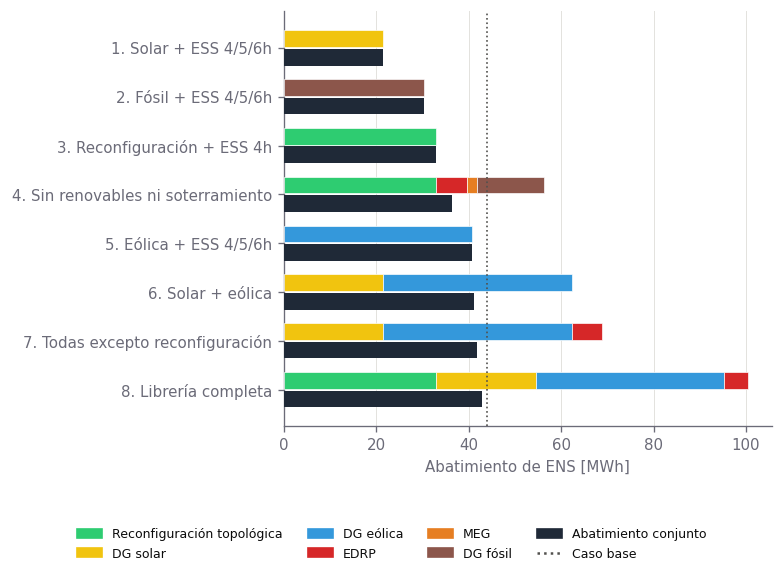

→ combinaciones_solapamiento_saidi


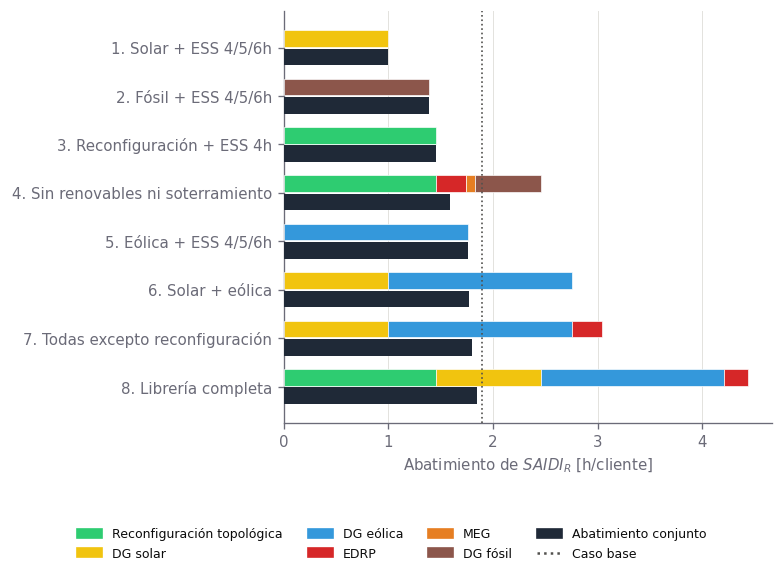

→ combinaciones_solapamiento_saifi


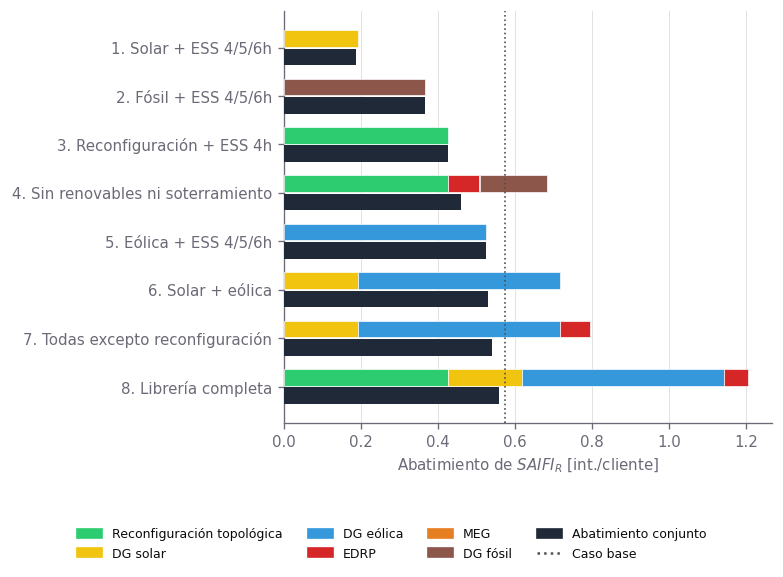

,ens conjunto/suma,ens suma,saidi conjunto/suma,saidi suma,saifi conjunto/suma,saifi suma
Solar + ESS 4/5/6h,1.000,21497.533,1.000,1.000,0.985,0.191
Fósil + ESS 4/5/6h,1.000,30373.495,1.000,1.388,0.999,0.367
Reconfiguración + ESS 4h,1.000,32983.719,1.000,1.454,1.000,0.426
Sin renovables ni soterramiento,0.645,56322.974,0.647,2.461,0.673,0.682
Eólica + ESS 4/5/6h,1.000,40739.736,1.000,1.759,1.002,0.525
Solar + eólica,0.660,62237.269,0.643,2.759,0.739,0.716
Todas excepto reconfiguración,0.606,68897.506,0.591,3.045,0.678,0.796
Librería completa,0.426,100515.920,0.416,4.442,0.463,1.207


In [8]:
# ── Figura A · abatimiento conjunto vs suma de individuales ─────────────
# La suma considera solo las medidas activas: en cada escenario se suma el
# abatimiento individual de las medidas que la combinación efectivamente activa,
# y luego se promedia sobre los escenarios.
# Un archivo por indicador: combinaciones_solapamiento_ens / _saidi / _saifi
resumen_solap = {}
for ind, titulo, escala, unidad in INDICADORES:
    fig, ax = plt.subplots(figsize=(6.6, 4.8))
    y = np.arange(len(comb))[::-1]          # N° 1 arriba
    h = 0.38
    usadas = set()
    for yi, (_, f) in zip(y, comb.iterrows()):
        caso = f['_caso']
        izquierda = 0.0
        for m in ORDEN_MEDIDAS:
            if m not in miembros[caso]:
                continue
            aporte = np.mean([max(float(D_IND.loc[(m, e), f'd_{ind}']), 0.0)
                              if m in ACTIVA[(caso, e)] else 0.0
                              for e in ESCENARIOS]) / escala
            if aporte <= 1e-6:              # no activa o ruido del solver
                continue
            ax.barh(yi + h/2, aporte, h * 0.9, left=izquierda, color=COLOR_MEDIDA[m],
                    edgecolor='white', linewidth=0.4, zorder=3)
            izquierda += aporte
            usadas.add(m)
        conjunto = f[f'd_{ind}'] / escala
        ax.barh(yi - h/2, conjunto, h * 0.9, color=COLOR_CONJUNTO, zorder=3)
        resumen_solap.setdefault(f['Nombre'], {})[f'{ind} conjunto/suma'] = (
            conjunto / izquierda if izquierda > 0 else np.nan)
        resumen_solap[f['Nombre']][f'{ind} suma'] = izquierda * escala
    base = float(ESPERADOS[f'{ind}_base'].iloc[0]) / escala
    ax.axvline(base, color=TINTA_2, lw=1, ls=':', zorder=4)
    ax.set_yticks(y, [f"{n}. {nom}" for n, nom in zip(comb['N'], comb['Nombre'])])
    ax.set_xlabel(f'Abatimiento de {titulo} [{unidad}]')
    if ind == 'ens':
        ax.xaxis.set_major_formatter(EJE_MILES)
    ax.grid(True, axis='x'); ax.set_axisbelow(True)
    manejadores = [mpl.patches.Patch(color=COLOR_MEDIDA[m], label=NOMBRE_MEDIDA[m])
                   for m in ORDEN_MEDIDAS if m in usadas]
    manejadores += [mpl.patches.Patch(color=COLOR_CONJUNTO, label='Abatimiento conjunto'),
                    mpl.lines.Line2D([], [], color=TINTA_2, ls=':', label='Caso base')]
    fig.legend(handles=manejadores, loc='lower center', ncol=4, fontsize=7.5,
               bbox_to_anchor=(0.5, 0.0), frameon=False)
    fig.tight_layout(rect=(0, 0.14, 1, 1))
    guardar(fig, f'combinaciones_solapamiento_{ind}')
    plt.show()
pd.DataFrame(resumen_solap).T.round(3)

→ combinaciones_costo_reduccion_ens


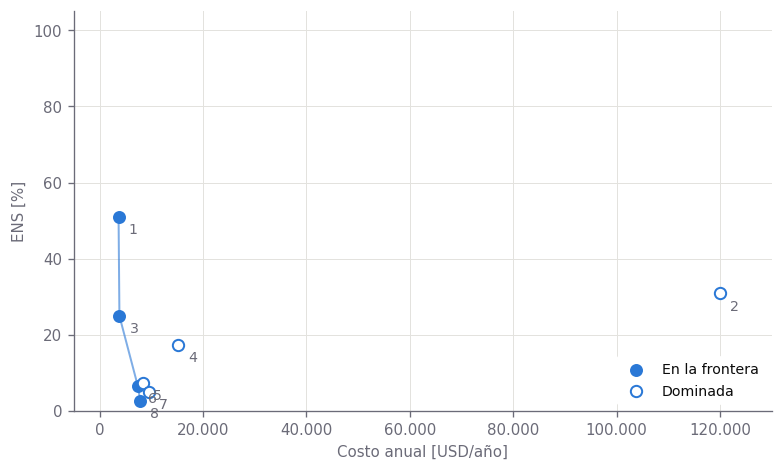

→ combinaciones_costo_reduccion_saidi


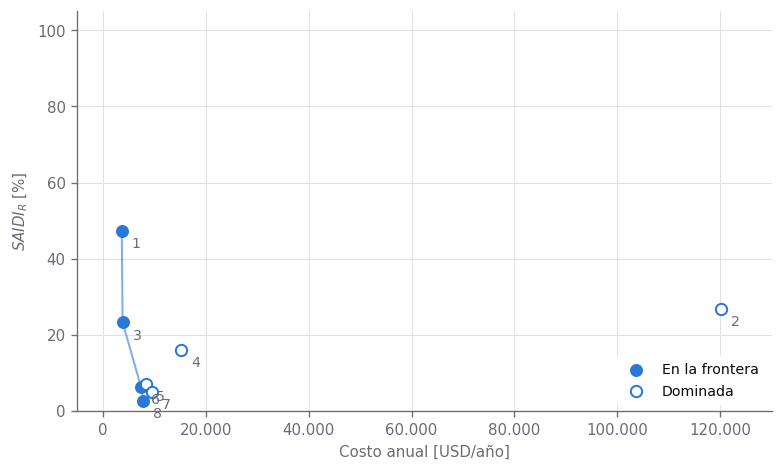

→ combinaciones_costo_reduccion_saifi


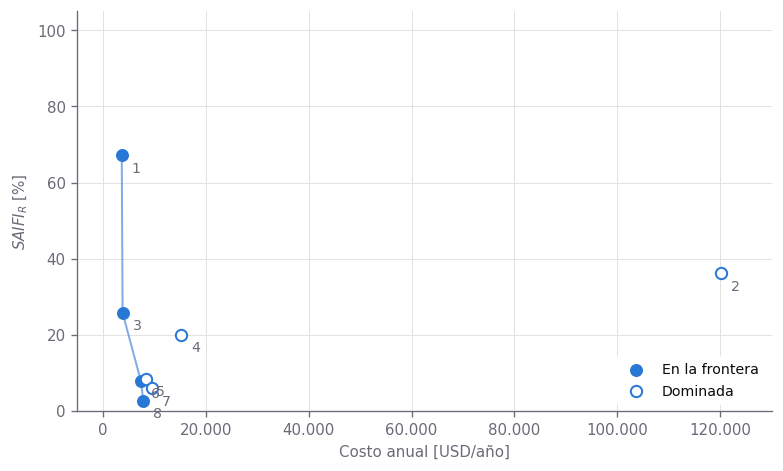

Combinaciones en la frontera (N°): {'ens': [1, 3, 6, 8], 'saidi': [1, 3, 6, 8], 'saifi': [1, 3, 6, 8]}


In [9]:
# ── Figura B · costo anual vs reducción, con frontera eficiente ─────────
# Una combinación está en la frontera si ninguna otra más barata reduce más.
# Un archivo por indicador: combinaciones_costo_reduccion_ens / _saidi / _saifi
frontera_por_ind = {}
for ind, titulo, _, _ in INDICADORES:
    fig, ax = plt.subplots(figsize=(6.6, 4.0))
    d = comb.assign(x=comb['cst_costo_total'], y=100-100 * comb[f'd_{ind}_pct']).sort_values('x')
    mejor, en_frontera = np.inf, []
    for _, f in d.iterrows():
        en_frontera.append(f['y'] < mejor)
        mejor = min(mejor, f['y'])
    d['frontera'] = en_frontera
    fr = d[d['frontera']]
    ax.plot(fr['x'], fr['y'], color=COLOR_CARTERA, lw=1.2, alpha=0.6, zorder=2)
    ax.scatter(fr['x'], fr['y'], s=46, color=COLOR_CARTERA, zorder=3, label='En la frontera')
    dom = d[~d['frontera']]
    ax.scatter(dom['x'], dom['y'], s=46, facecolor='white', edgecolor=COLOR_CARTERA,
               linewidth=1.2, zorder=3, label='Dominada')
    for _, f in d.iterrows():
        ax.annotate(str(f['N']), (f['x'], f['y']), textcoords='offset points', xytext=(6, -10),
                    fontsize=8.5, color=TINTA)
    ax.set_xlabel('Costo anual [USD/año]')
    ax.xaxis.set_major_formatter(EJE_MILES)
    ax.set_ylabel(f'{titulo} [%]')
    ax.set_xlim(-5000, 130000); ax.set_ylim(0, 105)
    ax.grid(True); ax.set_axisbelow(True)
    ax.legend(loc='lower right')
    fig.tight_layout()
    guardar(fig, f'combinaciones_costo_reduccion_{ind}')
    plt.show()
    frontera_por_ind[ind] = fr['N'].tolist()
print('Combinaciones en la frontera (N°):', frontera_por_ind)

In [10]:
# ── Rangos de la librería completa por nodo y por línea ─────────────────────
# Solo lo que efectivamente se usa en al menos un escenario. Se verifica además
# que las medidas no utilizadas quedan en cero en los 10 escenarios.
nombre_linea = BV.P._cargar('red.pkl')['net'].line['name'].to_dict()
plan, ubic, edrp = {}, {}, {}
for e in ESCENARIOS:
    reg = json.loads((TANDA / 'combinadas' / CARTERA / f'esc_{e:03d}.json').read_text(encoding='utf-8'))
    for k, d in reg['plan'].items():
        for el, x in (d.items() if isinstance(d, dict) else [('_', d)]):
            plan.setdefault(k, {}).setdefault(str(el), {})[e] = float(x)
    for k in ('tie_horas_cerrada', 'tie_maniobras'):
        for el, x in (reg.get('ubicacion') or {}).get(k, {}).items():
            ubic.setdefault(k, {}).setdefault(str(el), {})[e] = float(x)
    with np.load(TANDA / 'combinadas' / CARTERA / f'esc_{e:03d}.npz') as z:
        for bus, x in zip(z['BUSES'], z['E_EDRP_bus']):
            edrp.setdefault(str(int(bus)), {})[e] = float(x)

filas = []
def agrega(medida, elemento, unidad, valores):
    v = np.array([valores.get(e, 0.0) for e in ESCENARIOS], float)
    if (np.abs(v) > 1e-6).any():
        filas.append(dict(Medida=medida, Elemento=elemento, Unidad=unidad,
                          Escenarios=int((np.abs(v) > 1e-6).sum()),
                          Min=v.min(), Max=v.max(), Media=v.mean()))

ETIQ_PLAN = {'CAP_DG_sol_kW': ('DG solar', 'kW'), 'CAP_DG_eol_kW': ('DG eólica', 'kW')}
print('Claves de plan distintas de DG solar y eólica:', sorted(set(plan) - set(ETIQ_PLAN)))
for k, (med, un) in ETIQ_PLAN.items():
    for el in sorted(plan.get(k, {}), key=int):
        agrega(med, f'Bus {el}', un, plan[k][el])
for el in sorted(ubic.get('tie_horas_cerrada', {}), key=int):
    enlace = nombre_linea[int(el)].removeprefix('Line ')
    agrega('Reconfiguración', f'Enlace {enlace}', 'h cerrado', ubic['tie_horas_cerrada'][el])
    agrega('Reconfiguración', f'Enlace {enlace}', 'maniobras', ubic['tie_maniobras'][el])
for el in sorted(edrp, key=int):
    agrega('EDRP', f'Bus {el}', 'kWh', edrp[el])
rangos = pd.DataFrame(filas)
rangos.to_csv(TESIS / 'rangos_libreria_completa.csv', index=False, encoding='utf-8-sig')

no_usadas = COM_E[COM_E['combinacion'] == CARTERA][
    ['cap_dg_fos_kW', 'cap_ess_4h_kWh', 'cap_ess_5h_kWh', 'cap_ess_6h_kWh',
     'cap_meg_MW', 'cap_mess_MWh', 'km_ref', 'km_ug']].abs().max()
print('Máximo en los 10 escenarios de las medidas no utilizadas:', no_usadas.round(6).to_dict())
print('Totales por escenario DG solar / eólica [kW]:',
      {k: sorted({round(sum(plan[k][el].get(e, 0) for el in plan[k]), 1) for e in ESCENARIOS})
       for k in ETIQ_PLAN})
rangos.round(1)

Claves de plan distintas de DG solar y eólica: ['x_ref']
Máximo en los 10 escenarios de las medidas no utilizadas: {'cap_dg_fos_kW': 0.0, 'cap_ess_4h_kWh': 0.0, 'cap_ess_5h_kWh': 0.0, 'cap_ess_6h_kWh': 0.0, 'cap_meg_MW': 0.0, 'cap_mess_MWh': 0.0, 'km_ref': 0.65, 'km_ug': 0.0}
Totales por escenario DG solar / eólica [kW]: {'CAP_DG_sol_kW': [13422.6], 'CAP_DG_eol_kW': [12958.0, 12986.3, 13029.0, 13037.1, 13042.5, 13044.0, 13055.1, 13068.7]}


,Medida,Elemento,Unidad,Escenarios,Min,Max,Media
0,DG solar,Bus 1,kW,10,4045.4,7247.4,6280.1
1,DG solar,Bus 3,kW,5,0.0,293.2,81.3
2,DG solar,Bus 4,kW,5,0.0,2933.8,886.1
3,DG solar,Bus 12,kW,9,0.0,6175.2,4828.8
4,DG solar,Bus 13,kW,5,0.0,1775.2,225.9
5,DG solar,Bus 14,kW,6,0.0,6175.2,1120.4
6,DG eólica,Bus 1,kW,10,3953.1,6264.0,5142.8
7,DG eólica,Bus 3,kW,10,260.9,733.5,462.4
8,DG eólica,Bus 4,kW,10,618.2,2748.5,1600.8
9,DG eólica,Bus 12,kW,10,4520.5,5687.0,5290.7


## 3. ENS por zona y horaria (figuras de la app)

In [11]:
# # Mismas figuras que la app (graficos_valor_esperado.promediar_ens + figuras_ens):
# # ENS por zona y ENS total horaria, promedio equiprobable sobre los 10 escenarios.
# # Para la tesis solo cambia el fondo (blanco en vez de transparente) y la leyenda,
# # que en la app queda cortada.
# import barrido_vista as BV
# from graficos_valor_esperado import promediar_ens, figuras_ens

# red = BV.P._cargar('red.pkl')
# bases = [BV.P.base_dir('sec-0-2-9-10') / f'esc_{e:03d}.npz' for e in ESCENARIOS]
# rutas = [TANDA / 'combinadas' / CARTERA / f'esc_{e:03d}.npz' for e in ESCENARIOS]
# horario, zonal = promediar_ens(rutas, bases, red['BUSES'], red['bus_zone'], 8760)
# assert np.allclose(zonal['Caso base'], MUESTRA['ENS_zonal_base'], rtol=1e-6)
# assert np.allclose(zonal['Con medida'], MUESTRA['ENS_zonal_combinada'], rtol=1e-6, atol=1)

# fig_zona, fig_hora = figuras_ens(horario, zonal, 'Planificación propuesta')
# for fig in (fig_zona, fig_hora):
#     fig.update_layout(paper_bgcolor='white', plot_bgcolor='white',
#                       legend=dict(orientation='h', x=0, y=-0.22, font=dict(size=25),
#                                   itemwidth=40, entrywidthmode='pixels', entrywidth=380))
# fig_hora.update_layout(legend=dict(y=-0.3))
# fig_hora.data[1].line.color = '#56B4E9'   # celeste, como la figura de la app
# for fig in (fig_zona, fig_hora):
#     fig.update_layout(margin=dict(l=170))
#     fig.update_yaxes(title_standoff=25)

# for fig, nombre in ((fig_zona, 'ens_zona_base_cartera'), (fig_hora, 'ens_horaria_base_cartera')):
#     for ext in ('pdf', 'png'):
#         fig.write_image(TESIS / f'{nombre}.{ext}', scale=2)
#     copia_presentacion_plotly(fig, nombre, PRESENTACION)
#     print('→', nombre)
#     fig.show()

# pico = horario.loc[horario['Caso base'].idxmax()]
# print('Pico caso base: hora', int(pico['Hora']), '·', miles(pico['Caso base']), 'kWh · planificación',
#       miles(pico['Con medida'], 1), 'kWh')
# print('Horas con ENS > 1 kWh · base', int((horario['Caso base'] > 1).sum()),
#       '· planificación', int((horario['Con medida'] > 1).sum()))
# print('Máximo horario planificación:', miles(horario['Con medida'].max(), 1), 'kWh')
# print('Participación de cada zona en la ENS base:',
#       np.round(100 * zonal['Caso base'] / zonal['Caso base'].sum(), 1).tolist())

## 4. Comparación pareada por escenario

→ ens_pareada_escenarios


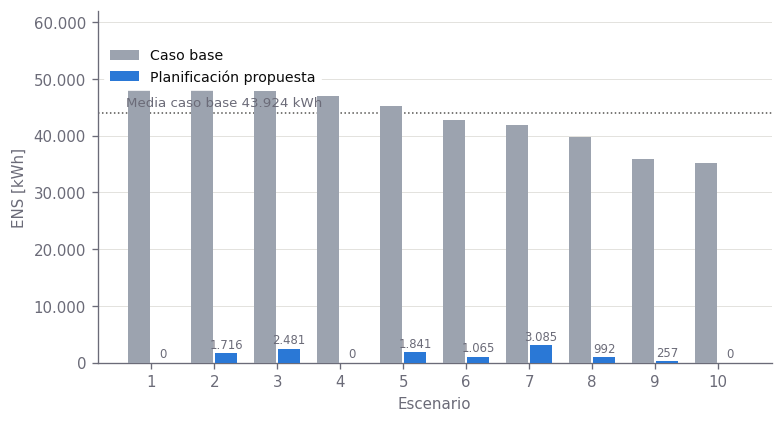

,Caso base,Planificación propuesta,Reducción %
escenario,,,
41,55279.4,0.0,100.0
93,48279.8,1715.8,96.4
1,47802.4,2481.4,94.8
21,47044.5,0.0,100.0
9,45250.6,1840.9,95.9
98,42723.5,1065.1,97.5
82,41977.2,3085.0,92.7
78,39775.2,991.9,97.5
57,35835.9,257.0,99.3


In [12]:
ind = pd.read_csv(TANDA / 'resumen_individual.csv')
com = pd.read_csv(TANDA / 'resumen_combinadas.csv')
VOLL = 5.0   # USD/kWh, uniforme (pipeline.py) y N_eventos = 1: costo_ens / ens
con_ens = ind['ens'] > 0   # con ENS nula el cociente es 0/0
assert np.allclose(ind.loc[con_ens, 'costo_ens'] / ind.loc[con_ens, 'ens'], VOLL)

base_e = ind.groupby('escenario')['cst_costo_ens_base'].first() / VOLL
cart_e = com[com['combinacion'] == CARTERA].set_index('escenario')['ens']
par = pd.DataFrame({'Caso base': base_e, 'Planificación propuesta': cart_e}).loc[ESCENARIOS]
par['Reducción %'] = 100 * (1 - par['Planificación propuesta'] / par['Caso base'])
par = par.sort_values('Caso base', ascending=False)   # escenario 1 = el de mayor ENS
assert np.isclose(par['Caso base'].mean(), ESPERADOS['ens_base'].iloc[0])

fig, ax = plt.subplots(figsize=(6.6, 3.6))
x = np.arange(len(par)); w = 0.38
ax.bar(x - w/2, par['Caso base'], w * 0.92, color=COLOR_BASE, label='Caso base', zorder=3)
ax.bar(x + w/2, par['Planificación propuesta'], w * 0.92, color=COLOR_CARTERA, label='Planificación propuesta', zorder=3)
for i, (b, c) in enumerate(zip(par['Caso base'], par['Planificación propuesta'])):
    ax.annotate(miles(c), (x[i] + w/2, c), textcoords='offset points', xytext=(0, 3),
                ha='center', fontsize=7, color=TINTA_2)
ax.axhline(par['Caso base'].mean(), color=TINTA_2, lw=0.9, ls=':')
ax.annotate(f"Media caso base {miles(par['Caso base'].mean())} kWh", (x[0] - 0.4, par['Caso base'].mean()),
            textcoords='offset points', xytext=(0, 4), fontsize=8, color=TINTA_2)
ax.set_xticks(x, [str(k) for k in range(1, len(par) + 1)])
ax.set(xlabel='Escenario', ylabel='ENS [kWh]')
ax.yaxis.set_major_formatter(EJE_MILES)
ax.grid(True, axis='y'); ax.set_axisbelow(True); ax.margins(y=0.12)
ax.legend(loc='upper left', bbox_to_anchor=(0, 0.93))
fig.tight_layout()
guardar(fig, 'ens_pareada_escenarios')
plt.show()
par.round(1)

## 5. Figuras de Lebú

Se generan y editan en `graficos_lebu.ipynb`; aquí solo se copian a la carpeta de la tesis con nombres estables. Correr antes `graficos_lebu.ipynb` si se cambió su estilo.

In [13]:
LEBU = APP / 'figuras_lebu'
COPIAS = {
    '01a_curva_fragilidad': 'lebu_fragilidad_medidas',
    '01b_fragilidad_vs_largo': 'lebu_fragilidad_largo',
    '02a_solar_dia_medio': 'lebu_solar_dia_medio',
    '02b_solar_mensual': 'lebu_solar_mensual',
    '02c_eolico_dia_medio': 'lebu_eolico_dia_medio',
    '02d_eolico_mensual': 'lebu_eolico_mensual',
    '03a_serie_viento_zona3': 'lebu_viento_zonas',   # contiene las tres zonas
    '04a_fallas_por_linea': 'lebu_fallas_por_linea',
    '04b_fallas_totales': 'lebu_fallas_totales',
}
for origen, destino in COPIAS.items():
    src = LEBU / f'{origen}.pdf'
    assert src.exists(), f'falta {src}: correr graficos_lebu.ipynb'
    shutil.copy2(src, TESIS / f'{destino}.pdf')
    print(f'{origen}.pdf → {destino}.pdf')

01a_curva_fragilidad.pdf → lebu_fragilidad_medidas.pdf
01b_fragilidad_vs_largo.pdf → lebu_fragilidad_largo.pdf
02a_solar_dia_medio.pdf → lebu_solar_dia_medio.pdf
02b_solar_mensual.pdf → lebu_solar_mensual.pdf
02c_eolico_dia_medio.pdf → lebu_eolico_dia_medio.pdf
02d_eolico_mensual.pdf → lebu_eolico_mensual.pdf
03a_serie_viento_zona3.pdf → lebu_viento_zonas.pdf
04a_fallas_por_linea.pdf → lebu_fallas_por_linea.pdf
04b_fallas_totales.pdf → lebu_fallas_totales.pdf


## 6. Planes de la matriz plan × escenario

Salida de `run_plan_fijo.py` en `plan_fijo/<cartera>/`. Cada plan `P<e>` es la inversión óptima de la librería completa para el escenario `e`, evaluada con esa inversión fija en los 10 escenarios. Misma figura y misma regla de frontera que la Figura B de las combinaciones, con costo anual e indicadores promediados sobre los 10 escenarios.

→ planes_costo_reduccion_ens


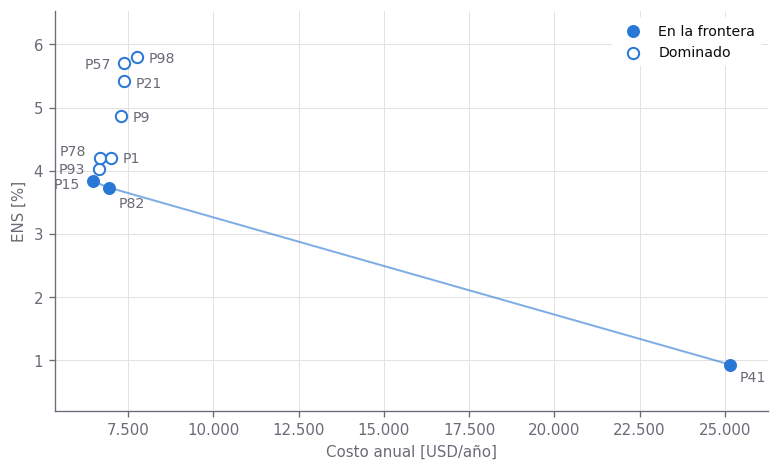

→ planes_costo_reduccion_saidi


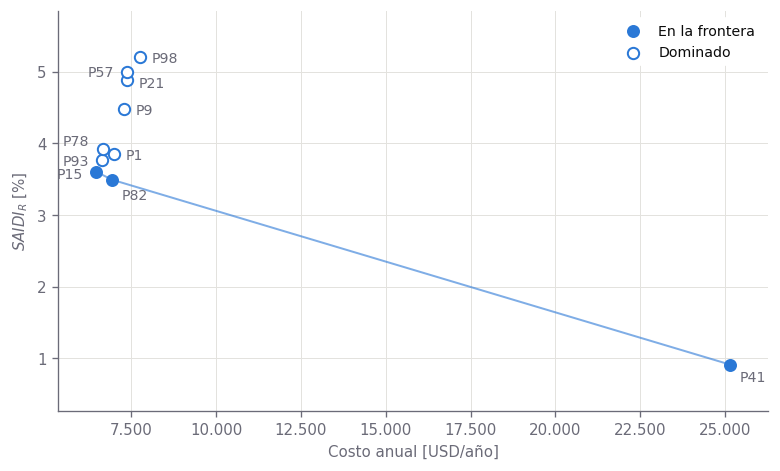

→ planes_costo_reduccion_saifi


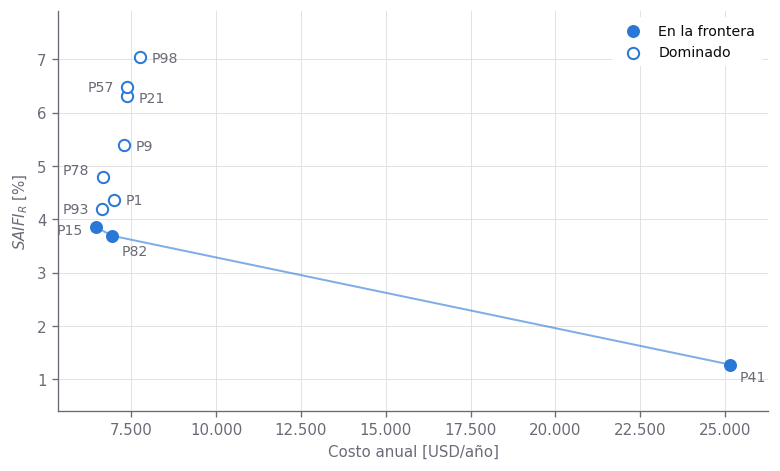

Planes en la frontera: {'ens': ['P15', 'P82', 'P41'], 'saidi': ['P15', 'P82', 'P41'], 'saifi': ['P15', 'P82', 'P41']}


,N,cst_costo_total,ens,saidi,saifi,ΔENS %,ΔSAIDI %,ΔSAIFI %
plan,,,,,,,,
1,P1,6995.796,1847.167,0.073,0.025,95.795,96.149,95.635
9,P9,7280.561,2137.916,0.085,0.031,95.133,95.523,94.605
15,P15,6476.545,1682.664,0.068,0.022,96.169,96.398,96.149
21,P21,7369.456,2381.963,0.092,0.036,94.577,95.122,93.688
41,P41,25148.347,407.242,0.017,0.007,99.073,99.086,98.725
57,P57,7388.653,2505.262,0.095,0.037,94.296,94.999,93.512
78,P78,6670.147,1842.916,0.074,0.027,95.804,96.078,95.211
82,P82,6937.619,1639.428,0.066,0.021,96.268,96.507,96.308
93,P93,6649.975,1769.827,0.071,0.024,95.971,96.232,95.804


In [14]:
# ── Planes · costo anual vs reducción, con frontera eficiente ───────────
# Un plan está en la frontera si ninguno más barato reduce más.
# Un archivo por indicador: planes_costo_reduccion_ens / _saidi / _saifi
MATRIZ = TANDA / 'plan_fijo' / CARTERA
LARGA = pd.read_csv(MATRIZ / 'matriz_larga.csv')
assert sorted(LARGA['escenario'].unique()) == sorted(ESCENARIOS)
assert (LARGA.groupby('plan').size() == len(ESCENARIOS)).all()      # matriz completa

planes = LARGA.groupby('plan')[['ens', 'saidi', 'saifi', 'cst_costo_total']].mean()
for ind, *_ in INDICADORES:
    # Igual que para las combinaciones: reducción del promedio respecto del caso base promedio.
    base = float(ESPERADOS[f'{ind}_base'].iloc[0])
    planes[f'd_{ind}_pct'] = (base - planes[ind]) / base
planes['N'] = [f'P{p}' for p in planes.index]

# Desplazamiento de etiquetas en puntos, para separar las que se tapan: {'P78': (-24, 4)}
DESPLAZA_PLAN = {'P15': (-24, -4), 'P93': (-24, -3), 'P78': (-24, 2), 'P57': (-24, -3),
                 'P1': (7, -3), 'P9': (7, -3), 'P21': (7, -4), 'P98': (7, -3), 'P82': (6, -12)}

frontera_planes = {}
for ind, titulo, _, _ in INDICADORES:
    fig, ax = plt.subplots(figsize=(6.6, 4.0))
    d = planes.assign(x=planes['cst_costo_total'], y=100 - 100 * planes[f'd_{ind}_pct']).sort_values('x')
    mejor, en_frontera = np.inf, []
    for _, f in d.iterrows():
        en_frontera.append(f['y'] < mejor)
        mejor = min(mejor, f['y'])
    d['frontera'] = en_frontera
    fr = d[d['frontera']]
    ax.plot(fr['x'], fr['y'], color=COLOR_CARTERA, lw=1.2, alpha=0.6, zorder=2)
    ax.scatter(fr['x'], fr['y'], s=46, color=COLOR_CARTERA, zorder=3, label='En la frontera')
    dom = d[~d['frontera']]
    ax.scatter(dom['x'], dom['y'], s=46, facecolor='white', edgecolor=COLOR_CARTERA,
               linewidth=1.2, zorder=3, label='Dominado')
    for _, f in d.iterrows():
        ax.annotate(f['N'], (f['x'], f['y']), textcoords='offset points',
                    xytext=DESPLAZA_PLAN.get(f['N'], (6, -10)), fontsize=8.5, color=TINTA)
    ax.set_xlabel('Costo anual [USD/año]')
    ax.xaxis.set_major_formatter(EJE_MILES)
    ax.set_ylabel(f'{titulo} [%]')
    ax.margins(x=0.06, y=0.15)
    ax.grid(True); ax.set_axisbelow(True)
    ax.legend(loc='upper right')
    fig.tight_layout()
    guardar(fig, f'planes_costo_reduccion_{ind}')
    plt.show()
    frontera_planes[ind] = fr['N'].tolist()
print('Planes en la frontera:', frontera_planes)
tabla_planes = planes.assign(**{f'Δ{i.upper()} %': 100 * planes[f'd_{i}_pct'] for i, *_ in INDICADORES})[
    ['N', 'cst_costo_total', 'ens', 'saidi', 'saifi', 'ΔENS %', 'ΔSAIDI %', 'ΔSAIFI %']]
tabla_planes.to_csv(TESIS / 'tabla_planes.csv', index=False, encoding='utf-8-sig')
tabla_planes.round(3)

## 7. Frontera de Pareto de los planes de la librería completa

Alternativas = los planes de la matriz plan × escenario (`run_plan_fijo.py`): `P<e>` es la inversión óptima de la librería completa para el escenario `e`, evaluada con esa inversión fija en los 10 escenarios. **La frontera se calcula escenario por escenario**: en el escenario `e` se comparan los 10 planes evaluados en `e`, más el caso base de `e` (inversión cero) como punto de partida para el knee point. El caso base no cambia qué planes son eficientes (cuesta 0 y ninguno lo domina) y no se dibuja para no aplastar la escala: su valor va en el título. La estrella marca el plan del propio escenario (`P<k>`, diagonal de la matriz). Los escenarios se numeran de 1 a 10 por severidad, como en la app (rango 1 = mayor ENS del caso base), y el plan `P<k>` es el optimizado para el escenario de rango `k`; el id original del escenario va entre paréntesis en los títulos y en la tabla de 7.3.

| métrica | origen |
|---|---|
| `capex_opex` | `cst_capex_anual + cst_opex_anual + sobrecosto DG` [USD/año] |
| `func_obj` | `capex_opex + cst_costo_ens_estr` [USD/año] |
| `ens`, `saidi`, `saifi` | columnas homónimas |

Con DG renovable el CAPEX y OPEX de la DG se cancelan vs el caso sin fallas del propio plan (`referencia_dg_plan`); su costo frente al óptimo sin fallas (E4) es el sobrecosto, que `matriz_larga.csv` no guarda y se recupera como `objetivo − cst_objetivo_plan`. En los gráficos (7.4) la dominancia se calcula con los mismos dos ejes de cada panel, así que el color de cada punto corresponde a lo que se ve. `OBJETIVOS_PARETO` (por defecto `capex_opex` y `ens`) solo define la tabla de 7.3 y el knee point. Knee point = máxima distancia a la recta entre los extremos de la frontera, con ejes normalizados.

In [2]:
# ── 7.1 Carga de la matriz plan × escenario (librería completa) ─────────────
# Cada plan P<e> es la inversión óptima de la librería completa para el
# escenario e (run_plan_fijo.py), evaluada con esa inversión fija en los 10
# escenarios. En un escenario dado, las alternativas son esos 10 planes.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

APP = Path.cwd()                                   # .../abc/mi_proyecto/app/app
TANDA_PARETO = 'sec-0-2-9-10 severo'               # carpeta de la tanda del barrido

# Busca la tanda en cualquier artefactos/**/barrido*/ (sobrevive a reordenar carpetas).
candidatas = sorted(p.parent for p in (APP / 'artefactos').rglob('resumen_individual.csv')
                    if p.parent.parent.name.startswith('barrido'))
nombradas = [p for p in candidatas if p.name == TANDA_PARETO]
assert nombradas, f'No encontré la tanda {TANDA_PARETO!r}. Disponibles: ' + \
    str([str(p.relative_to(APP)) for p in candidatas])
DIR_TANDA = nombradas[0]
matrices = sorted((DIR_TANDA / 'plan_fijo').glob('*/matriz_larga.csv'))
assert len(matrices) == 1, f'Esperaba una matriz plan × escenario, hay {len(matrices)}'
print('Matriz:', matrices[0].relative_to(APP))

# Métricas [USD/año]:
#   capex_opex = cst_capex_anual + cst_opex_anual + sobrecosto DG
#   func_obj   = capex_opex + cst_costo_ens_estr
# Con DG renovable el CAPEX/OPEX de la DG se cancela vs el caso sin fallas
# del propio plan (run_barrido_medidas.referencia_dg_plan); lo que cuesta esa DG
# frente al óptimo sin fallas (E4) es el sobrecosto. matriz_larga no lo guarda y
# se recupera con la identidad objetivo = cst_objetivo_plan + sobrecosto.
METRICAS = ['capex_opex', 'func_obj', 'ens', 'saidi', 'saifi']
larga = pd.read_csv(matrices[0])
PLANES = pd.DataFrame({'plan': 'P' + larga['plan'].astype(str),
                       'plan_de': larga['plan'].astype(int),
                       'escenario': larga['escenario'].astype(int),
                       'diagonal': larga['plan'] == larga['escenario']})
PLANES['sobrecosto_dg'] = larga['objetivo'] - larga['cst_objetivo_plan']
PLANES['capex_opex'] = larga['cst_capex_anual'] + larga['cst_opex_anual'] + PLANES['sobrecosto_dg']
PLANES['func_obj'] = PLANES['capex_opex'] + larga['cst_costo_ens_estr']
for col in ('ens', 'saidi', 'saifi'):
    PLANES[col] = larga[col]

ESC_PARETO = sorted(PLANES['escenario'].unique())
completa = PLANES.groupby('plan')['escenario'].nunique()
assert (completa == len(ESC_PARETO)).all(), completa[completa < len(ESC_PARETO)]
assert PLANES[METRICAS].notna().all().all()

# Caso base (sin medidas) de cada escenario: referencia para las reducciones.
variante = DIR_TANDA.name.split(' ')[0]
ruta_base = next((APP / 'artefactos').rglob(f'baselines*/{variante}/indicadores_base.json'))
bj = json.loads(ruta_base.read_text(encoding='utf-8'))
BASE = pd.DataFrame([dict(escenario=e, plan='Caso base', diagonal=False, sobrecosto_dg=0.0, capex_opex=0.0, func_obj=bj[f'esc_{e:03d}|8760']['costo_ens'],
                          **{k: bj[f'esc_{e:03d}|8760'][k] for k in ('ens', 'saidi', 'saifi')})
                     for e in ESC_PARETO]).set_index('escenario')

# Orden y numeración de la app (estudio_v8/analisis.muestra_mas_severa): los escenarios
# conservan su id (índice desde 0) y se ordenan por Rango, 1 = mayor ENS del caso base.
# En figuras y tablas el escenario se numera por su Rango (1 a 10) y el plan P<k> es el
# optimizado para el escenario de rango k; el id original queda entre paréntesis.
ESC_PARETO = list(BASE['ens'].sort_values(ascending=False, kind='stable').index)
RANGO = {e: k for k, e in enumerate(ESC_PARETO, 1)}
PLANES['plan'] = 'P' + PLANES['plan_de'].map(RANGO).astype(str)

# Control: el plan diagonal P<e> se optimizó para e, así que debería tener la
# menor función objetivo de la columna e (salvo el gap MIP).
mejor = PLANES.loc[PLANES.groupby('escenario')['func_obj'].idxmin(), ['escenario', 'plan']]
diag = PLANES[PLANES['diagonal']].set_index('escenario')
control = mejor.set_index('escenario').assign(
    diagonal=diag['plan'],
    exceso_diag_pct=100 * (diag['func_obj'] / PLANES.groupby('escenario')['func_obj'].min() - 1))
print(f'{PLANES["plan"].nunique()} planes × {len(ESC_PARETO)} escenarios · caso base: {ruta_base.relative_to(APP)}')
print('Plan con menor func_obj por escenario frente al diagonal:')
control.round(3)

Matriz: artefactos\validacion\barrido\sec-0-2-9-10 severo\plan_fijo\combo_reconfig_topo+dg_sol+dg_eol+dg_fos+ess_4h+ess_5h+ess_6h+meg+mess+edrp+refuerzo+soterramiento\matriz_larga.csv
10 planes × 10 escenarios · caso base: artefactos\validacion\baselines\sec-0-2-9-10\indicadores_base.json
Plan con menor func_obj por escenario frente al diagonal:


,plan,diagonal,exceso_diag_pct
escenario,,,
1,P3,P3,0.000
9,P5,P5,0.000
15,P10,P10,0.000
21,P4,P4,0.000
41,P1,P1,0.000
57,P9,P9,0.000
78,P9,P8,0.412
82,P7,P7,0.000
93,P2,P2,0.000


In [16]:
# ── 7.2 Filtro de Pareto y knee point ───────────────────────────────────────
def frontera_pareto(df, objetivos, rtol=1e-6):
    """Separa las soluciones no dominadas de las dominadas (todos los objetivos se minimizan).

    j domina a i si j no es peor que i en ningún objetivo y es estrictamente mejor
    en al menos uno. La tolerancia relativa `rtol` (sobre el rango de cada objetivo)
    evita que el ruido numérico del solver (~1e-6) cree dominancias ficticias entre
    soluciones prácticamente idénticas.
    Vectorizado por bloques: O(n²) en tiempo, O(bloque·n) en memoria.
    Devuelve (frontera ordenada por los objetivos, dominadas).
    """
    X = df[list(objetivos)].to_numpy(float)
    tol = rtol * np.maximum(np.ptp(X, axis=0), 1e-12)
    no_dom = np.ones(len(X), bool)
    for ini in range(0, len(X), 512):
        Xi = X[ini:ini + 512, None, :]                          # (b, 1, k)
        no_peor = (X[None] <= Xi + tol).all(-1)                 # (b, n)
        mejor = (X[None] < Xi - tol).any(-1)
        no_dom[ini:ini + 512] = ~(no_peor & mejor).any(1)
    return df[no_dom].sort_values(list(objetivos)), df[~no_dom]


def knee_point(frontera, x, y):
    """Knee point por máxima distancia a la recta entre los extremos de la frontera.

    Ambos ejes se normalizan a [0, 1] para que la escala (USD vs kWh) no sesgue
    la elección. Es el punto donde seguir invirtiendo deja de rendir reducciones
    comparables al costo adicional. Con dos puntos (caso base + un plan) el
    único plan eficiente es el knee; con uno solo no hay trade-off (None).
    """
    P = frontera[[x, y]].to_numpy(float)
    if len(P) < 3:
        return frontera.iloc[1] if len(P) == 2 else None
    Q = (P - P.min(0)) / np.where(np.ptp(P, 0) > 0, np.ptp(P, 0), 1)
    a, b = Q[0], Q[-1]
    v, w = b - a, Q - a
    dist = np.abs(v[0] * w[:, 1] - v[1] * w[:, 0]) / np.linalg.norm(v)
    return frontera.iloc[int(np.argmax(dist))]

In [17]:
# ── 7.3 Frontera por escenario ──────────────────────────────────────────────
# Cambiar a ['capex_opex', 'func_obj'] para definir la dominancia por la función objetivo.
OBJETIVOS_PARETO = ['capex_opex', 'ens']

def soluciones(e):
    """Los planes evaluados en el escenario e, más el caso base (inversión cero) como
    punto de partida de la curva: sin él, la frontera de 10 planes en un escenario
    tiene 1 a 3 puntos y el knee no queda definido."""
    base = BASE.loc[[e]].reset_index()
    return pd.concat([PLANES[PLANES['escenario'] == e], base], ignore_index=True)

def analizar(e):
    """Frontera, dominados y knee point del escenario e."""
    sol = soluciones(e)
    fr, dom = frontera_pareto(sol, OBJETIVOS_PARETO)
    return fr, dom, knee_point(fr, *OBJETIVOS_PARETO)

RES = {e: analizar(e) for e in ESC_PARETO}

filas = []
for e, (fr, dom, knee) in RES.items():
    d = PLANES[(PLANES['escenario'] == e) & PLANES['diagonal']].iloc[0]
    filas.append({'Escenario': RANGO[e], 'Id escenario': e, 'Frontera': ', '.join(fr.loc[fr['plan'] != 'Caso base', 'plan']),
                  'Knee': knee['plan'],
                  'Knee capex_opex': knee['capex_opex'], 'Knee ENS': knee['ens'],
                  'Knee ΔENS % vs base': 100 * (1 - knee['ens'] / BASE.loc[e, 'ens']),
                  'Diagonal': d['plan'], 'Diagonal en frontera': d['plan'] in set(fr['plan'])})
RESUMEN_PARETO = pd.DataFrame(filas).set_index('Escenario')
print('Veces que cada plan es knee:', RESUMEN_PARETO['Knee'].value_counts().to_dict())
print('Veces que cada plan está en la frontera:',
      pd.Series(', '.join(RESUMEN_PARETO['Frontera']).split(', ')).value_counts()
      .drop('Caso base', errors='ignore').to_dict())
RESUMEN_PARETO.round(1)

Veces que cada plan es knee: {'P10': 2, 'P9': 2, 'P3': 1, 'P2': 1, 'P4': 1, 'P5': 1, 'P6': 1, 'P7': 1}
Veces que cada plan está en la frontera: {'P1': 6, 'P10': 2, 'P7': 2, 'P9': 2, 'P2': 1, 'P3': 1, 'P4': 1, 'P5': 1, 'P6': 1}


,Id escenario,Frontera,Knee,Knee capex_opex,Knee ENS,Knee ΔENS % vs base,Diagonal,Diagonal en frontera
Escenario,,,,,,,,
1,41,"P10, P7, P1",P10,9525.4,4660.6,91.6,P1,True
2,93,"P2, P1",P2,6736.9,1715.8,96.4,P2,True
3,1,"P3, P1",P3,6793.1,2481.4,94.8,P3,True
4,21,P4,P4,6038.8,0.0,100.0,P4,True
5,9,"P5, P1",P5,6185.6,1840.9,95.9,P5,True
6,98,P6,P6,5524.4,1065.1,97.5,P6,True
7,82,"P7, P1",P7,7147.5,3085.0,92.7,P7,True
8,78,"P9, P1",P9,5194.4,991.9,97.5,P8,False
9,57,P9,P9,4468.2,257.0,99.3,P9,True


→ pareto_planes_esc_01


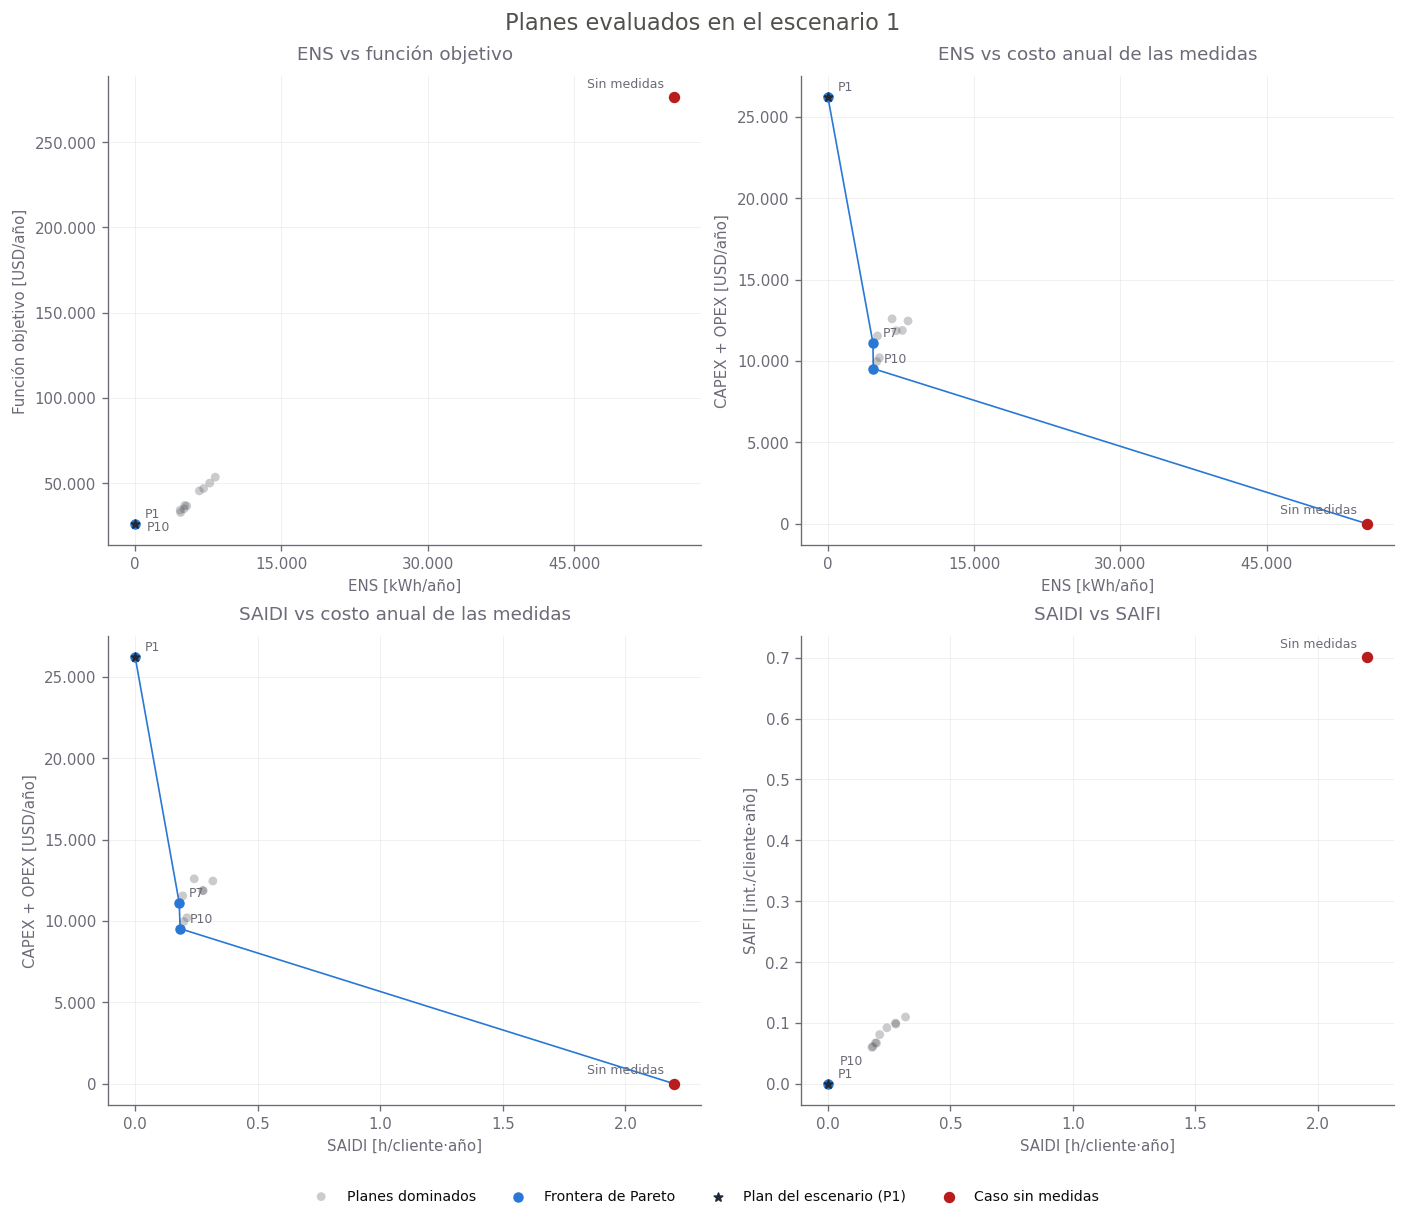

→ pareto_planes_esc_02


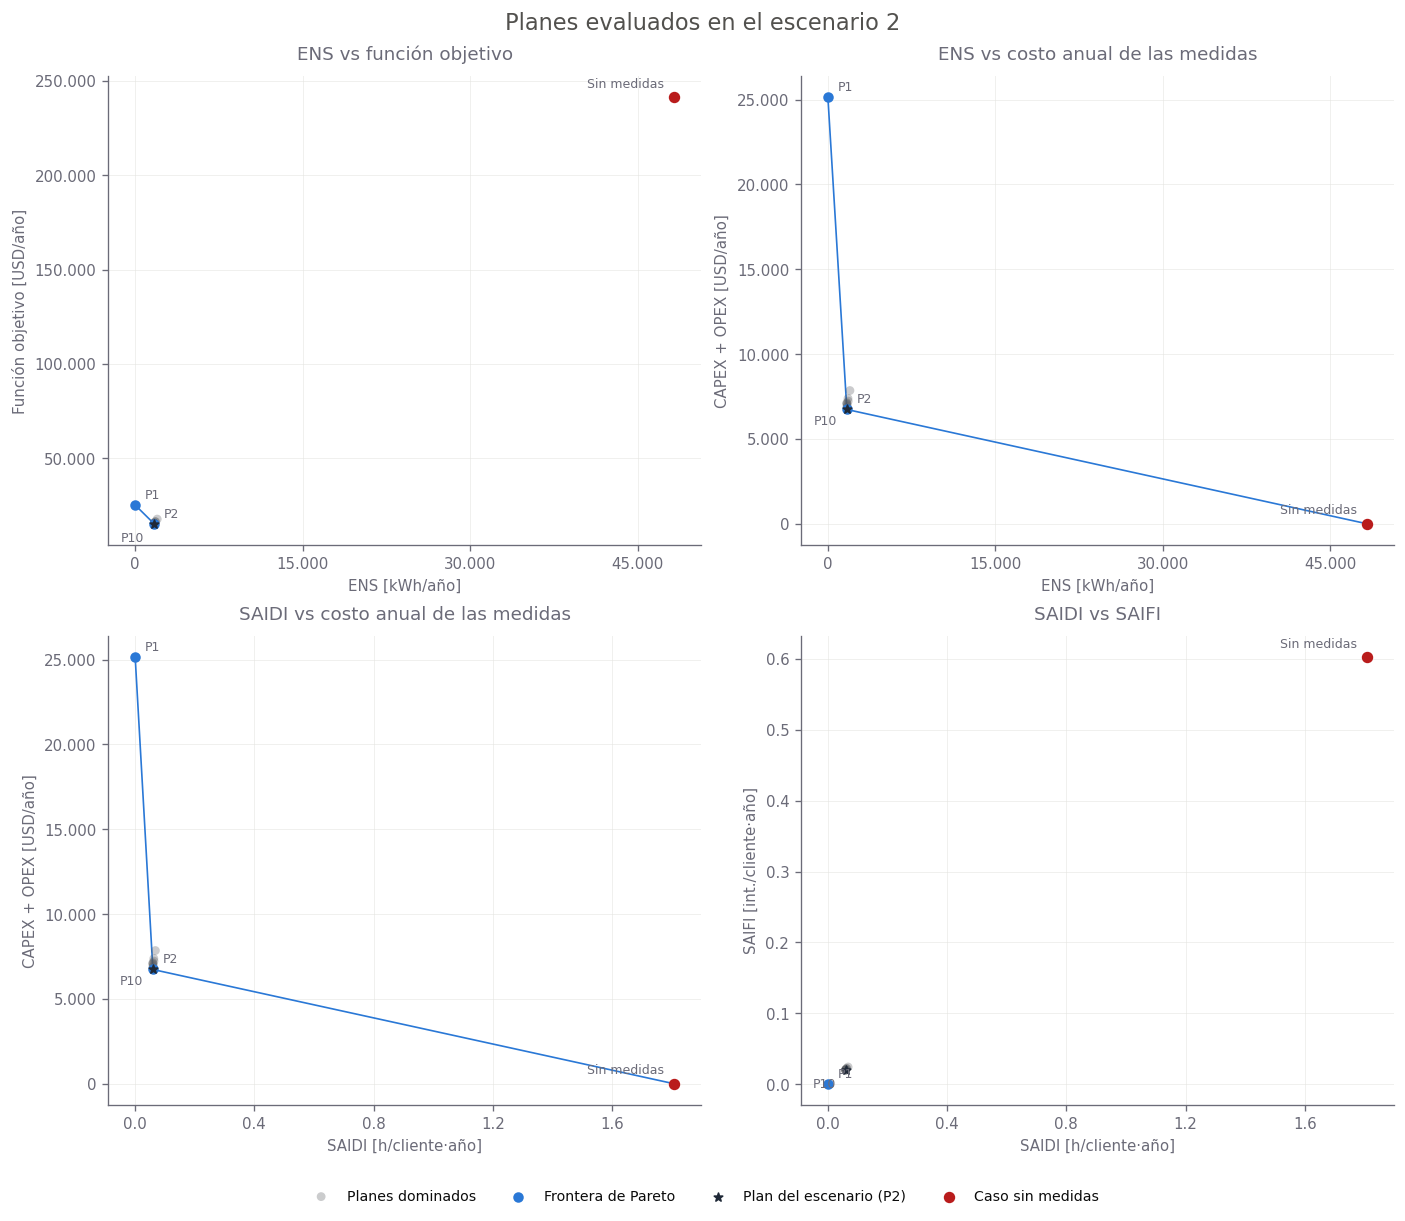

→ pareto_planes_esc_03


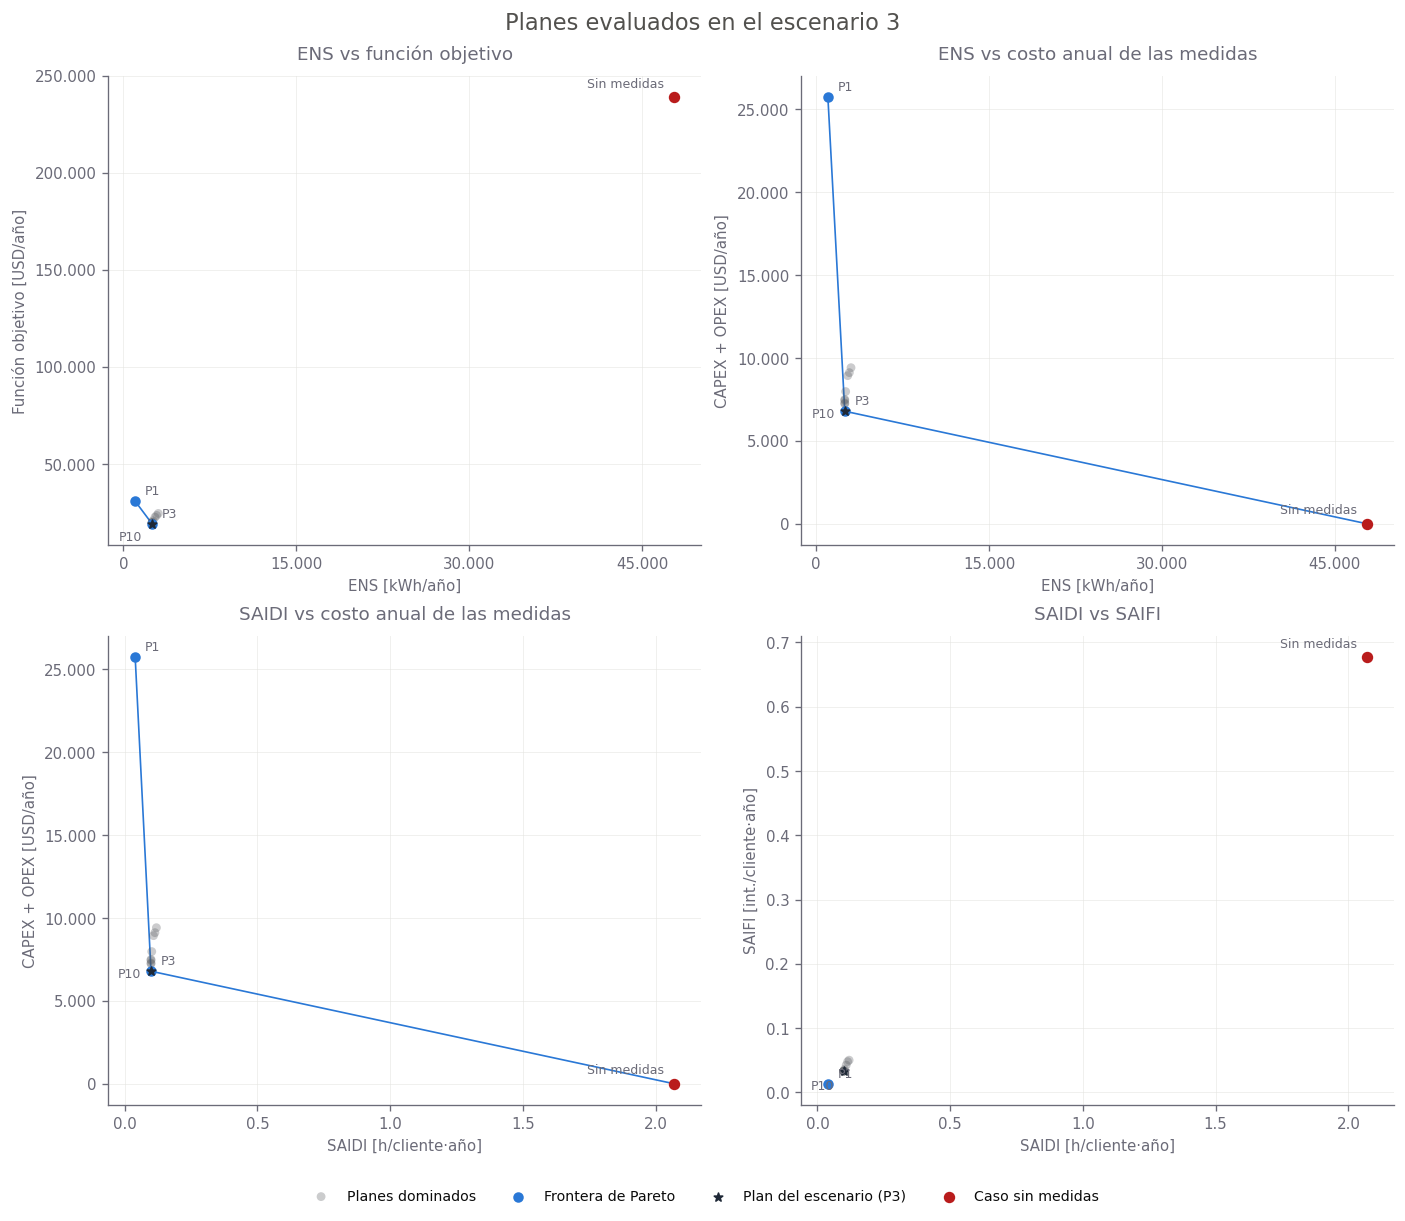

→ pareto_planes_esc_04


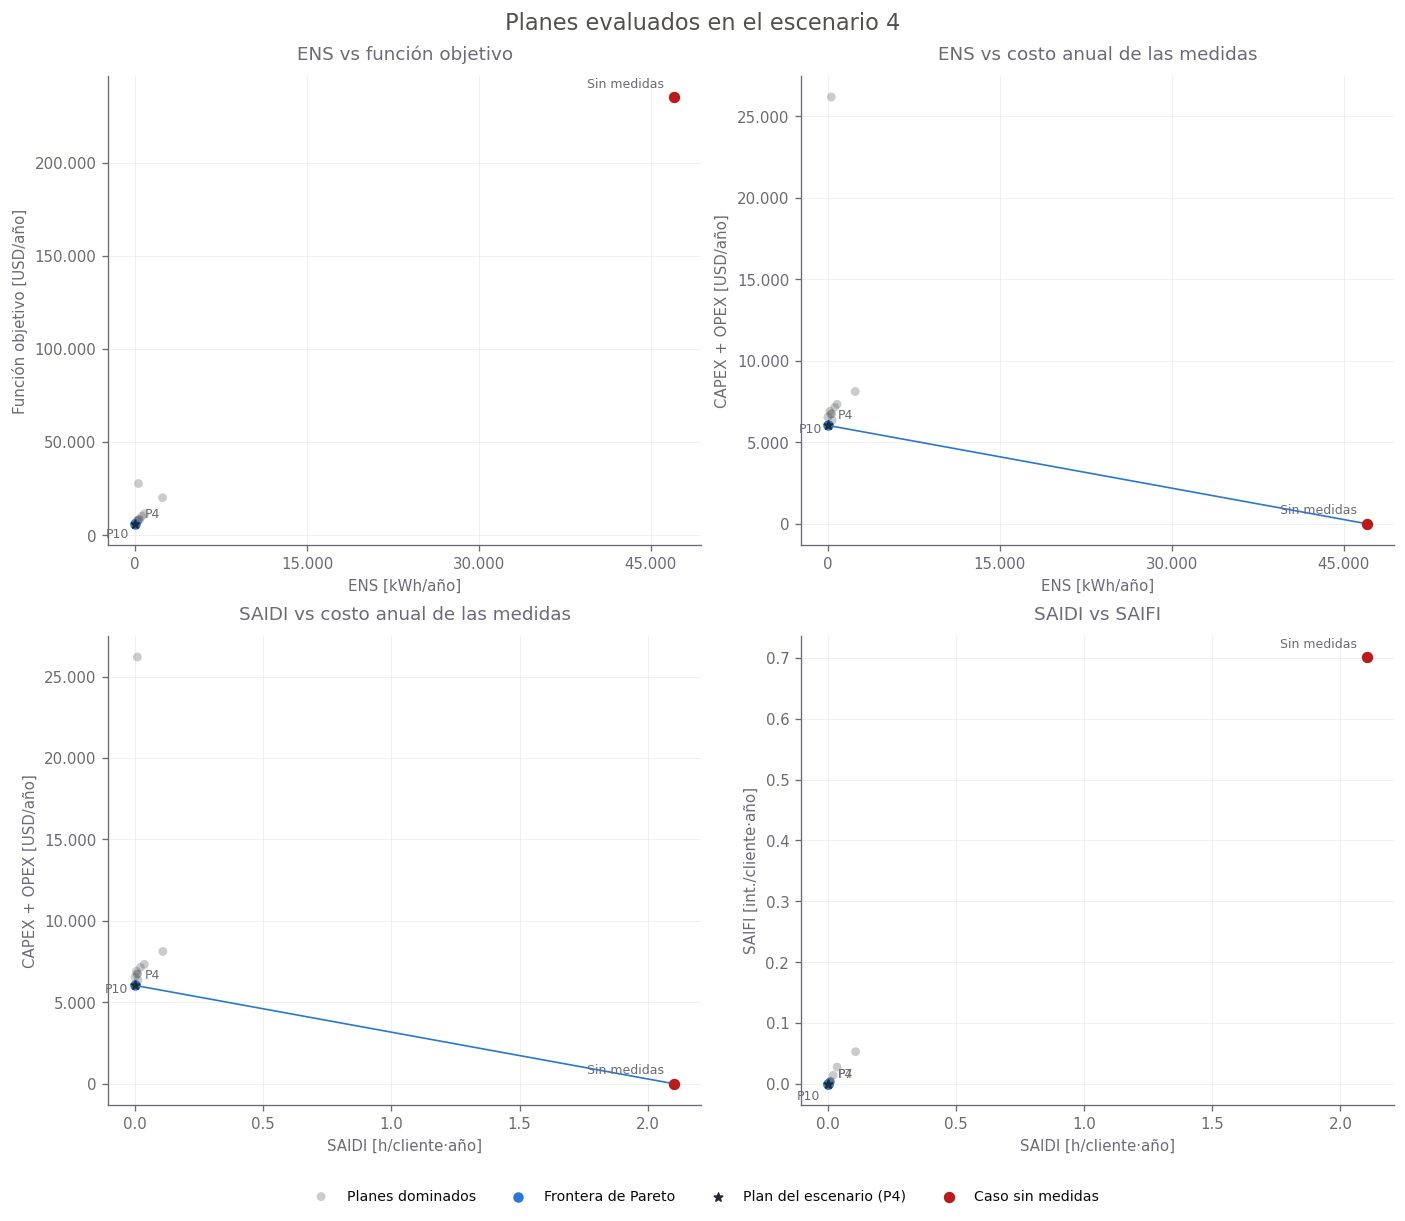

→ pareto_planes_esc_05


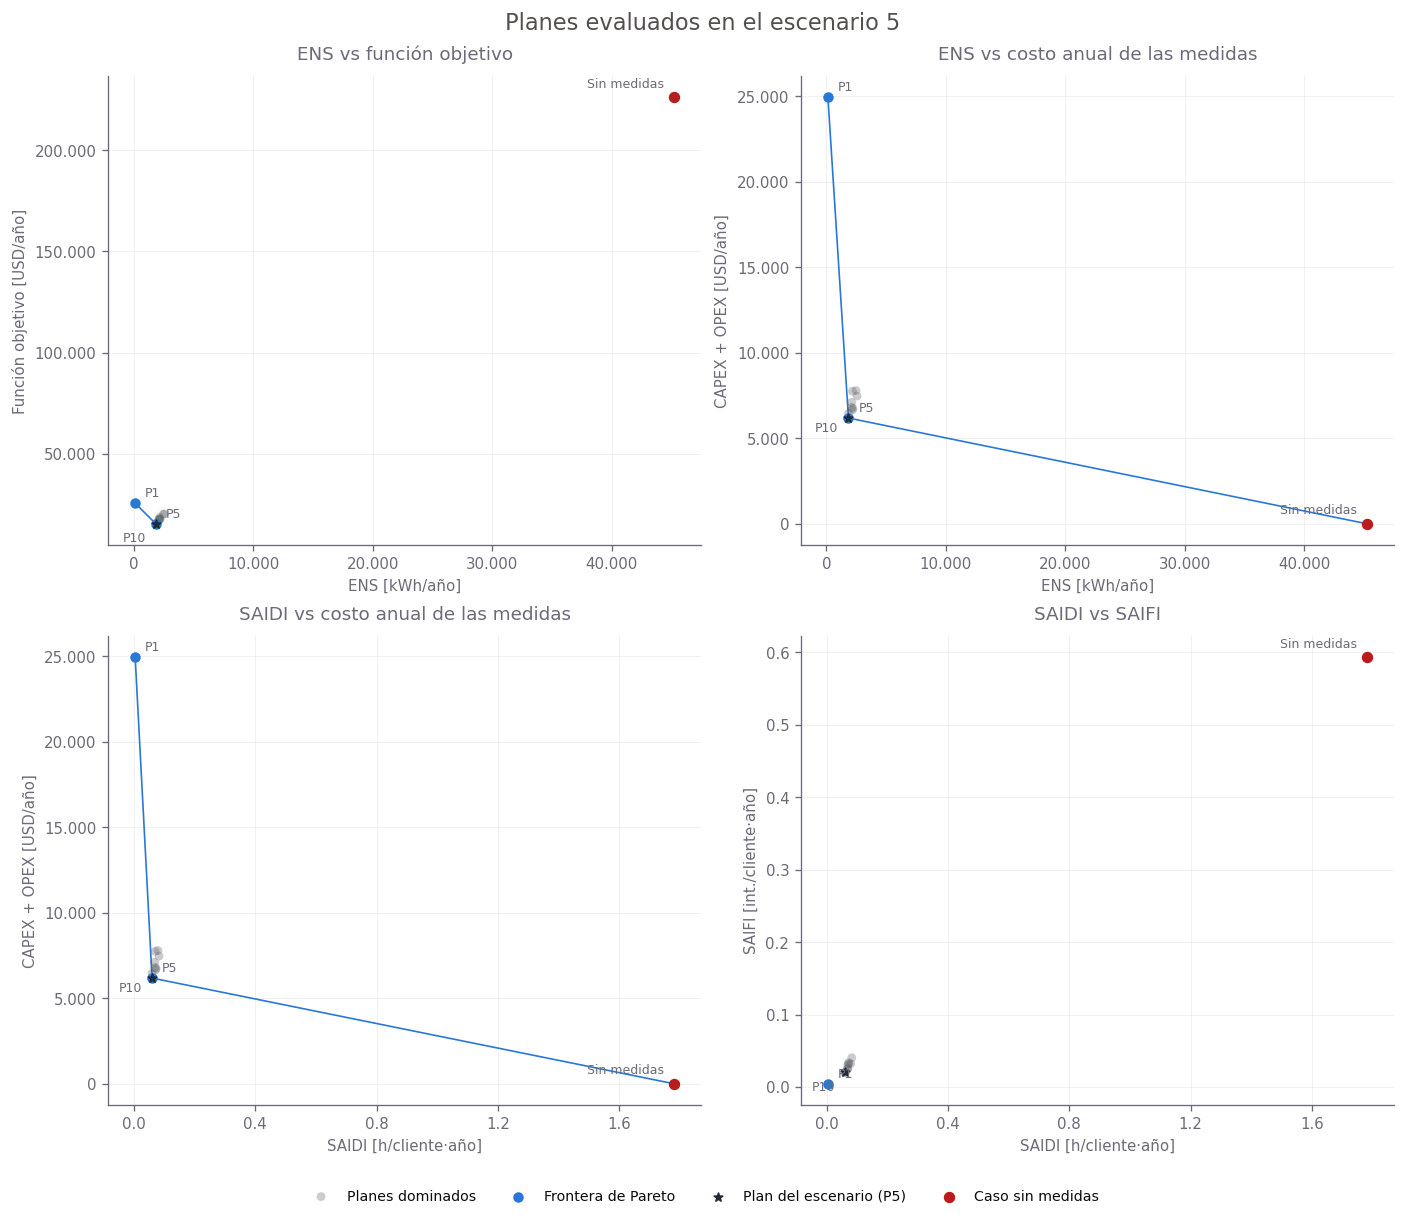

→ pareto_planes_esc_06


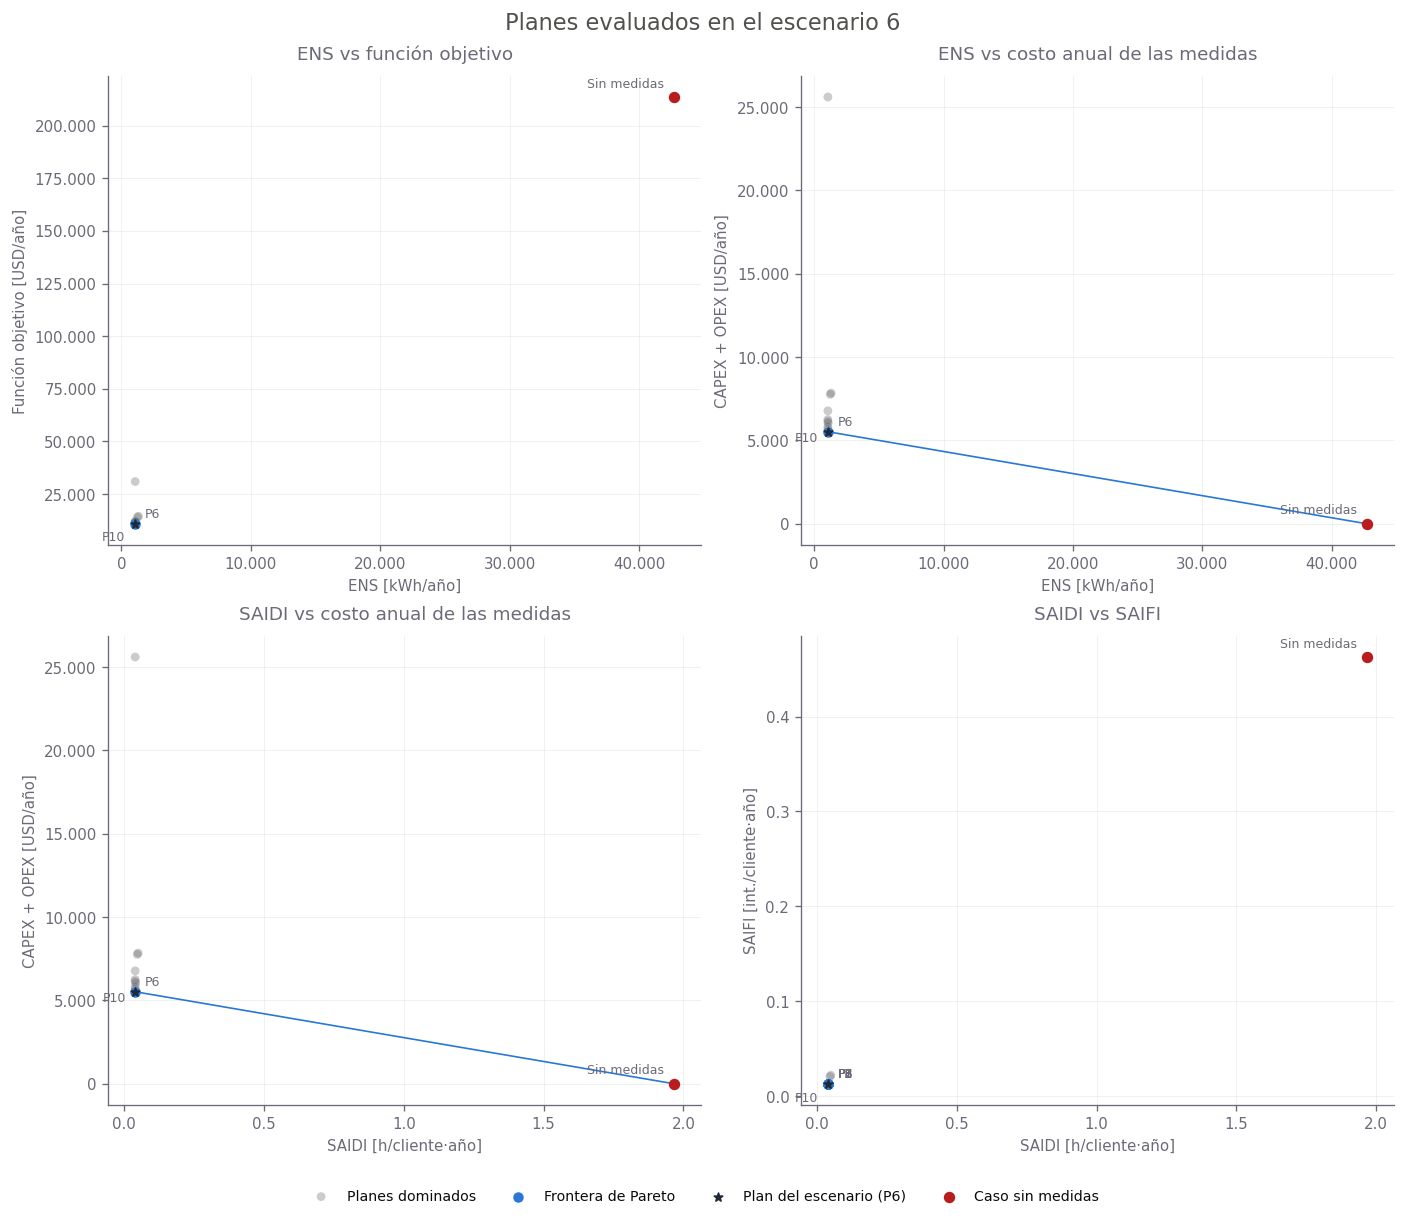

→ pareto_planes_esc_07


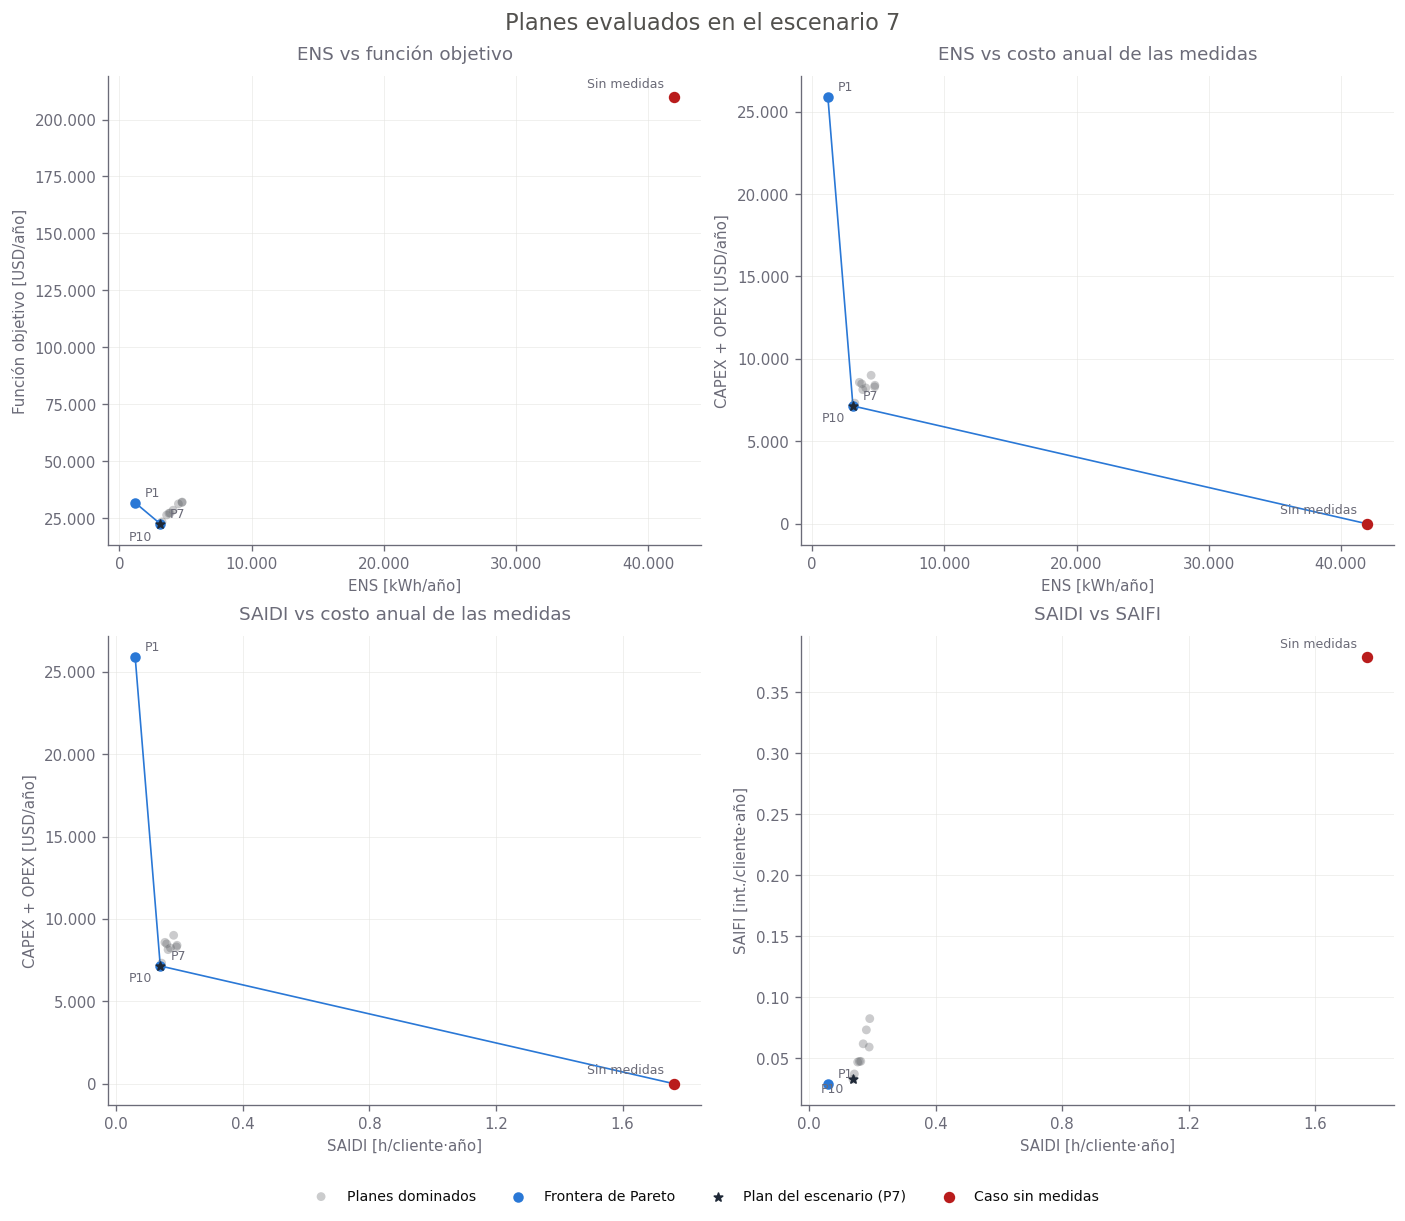

→ pareto_planes_esc_08


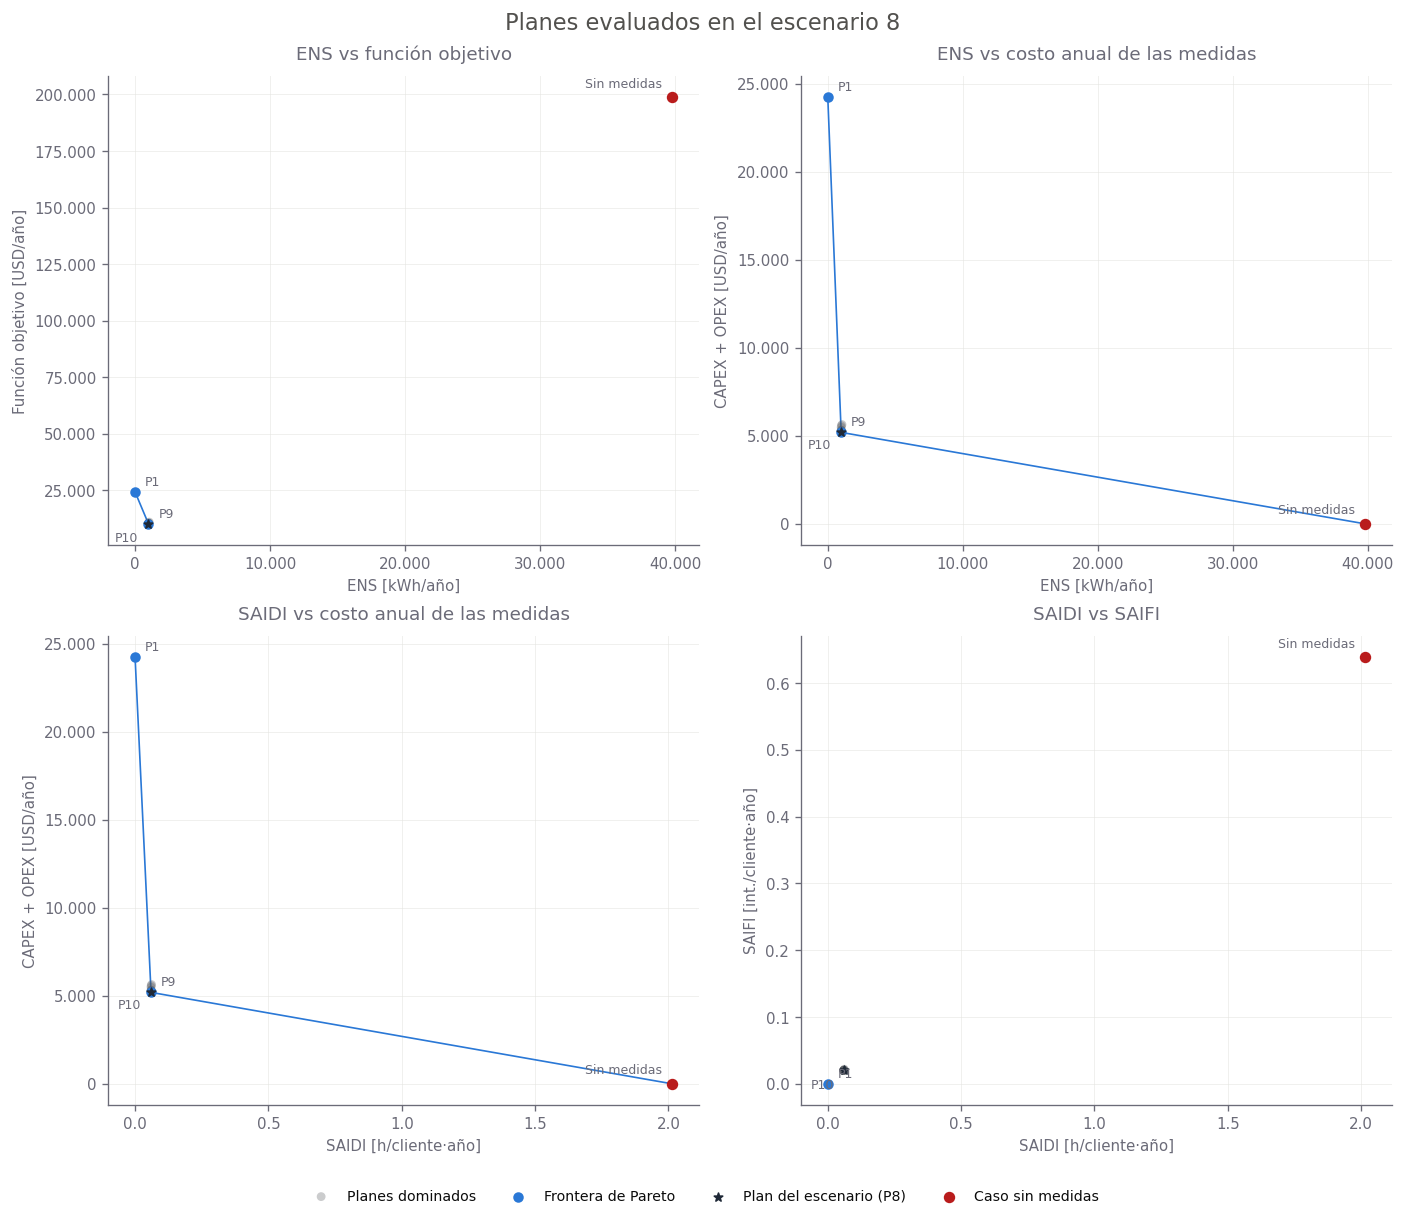

→ pareto_planes_esc_09


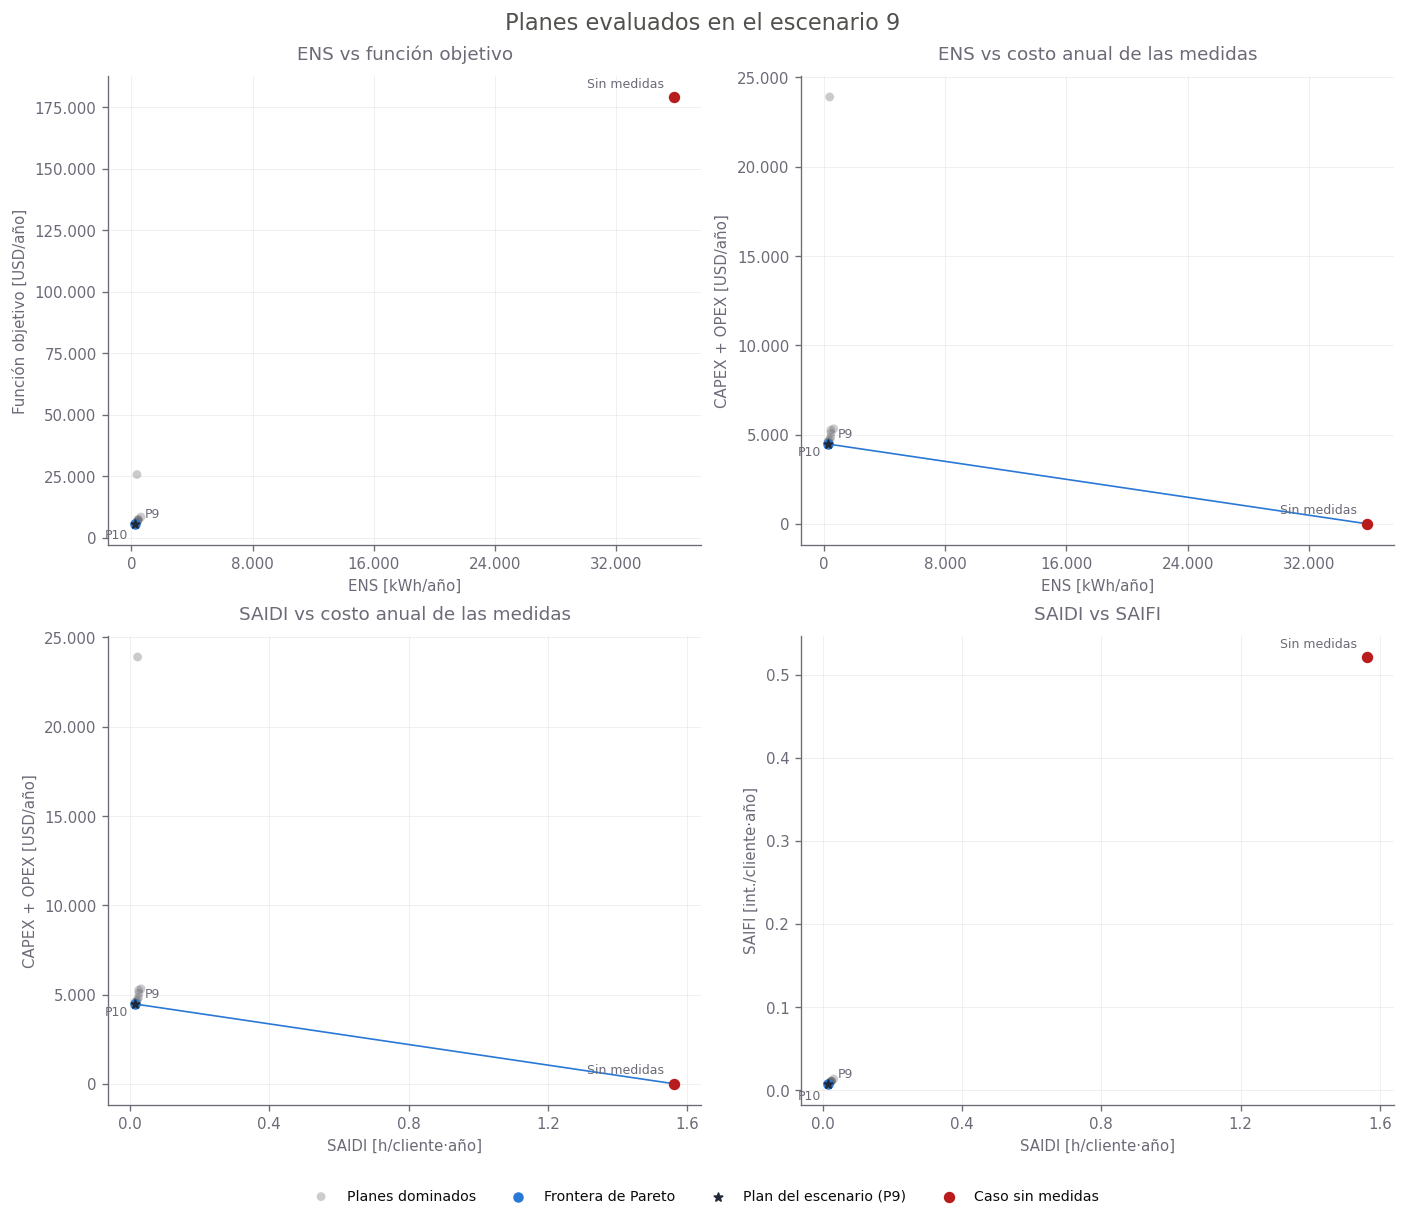

→ pareto_planes_esc_10


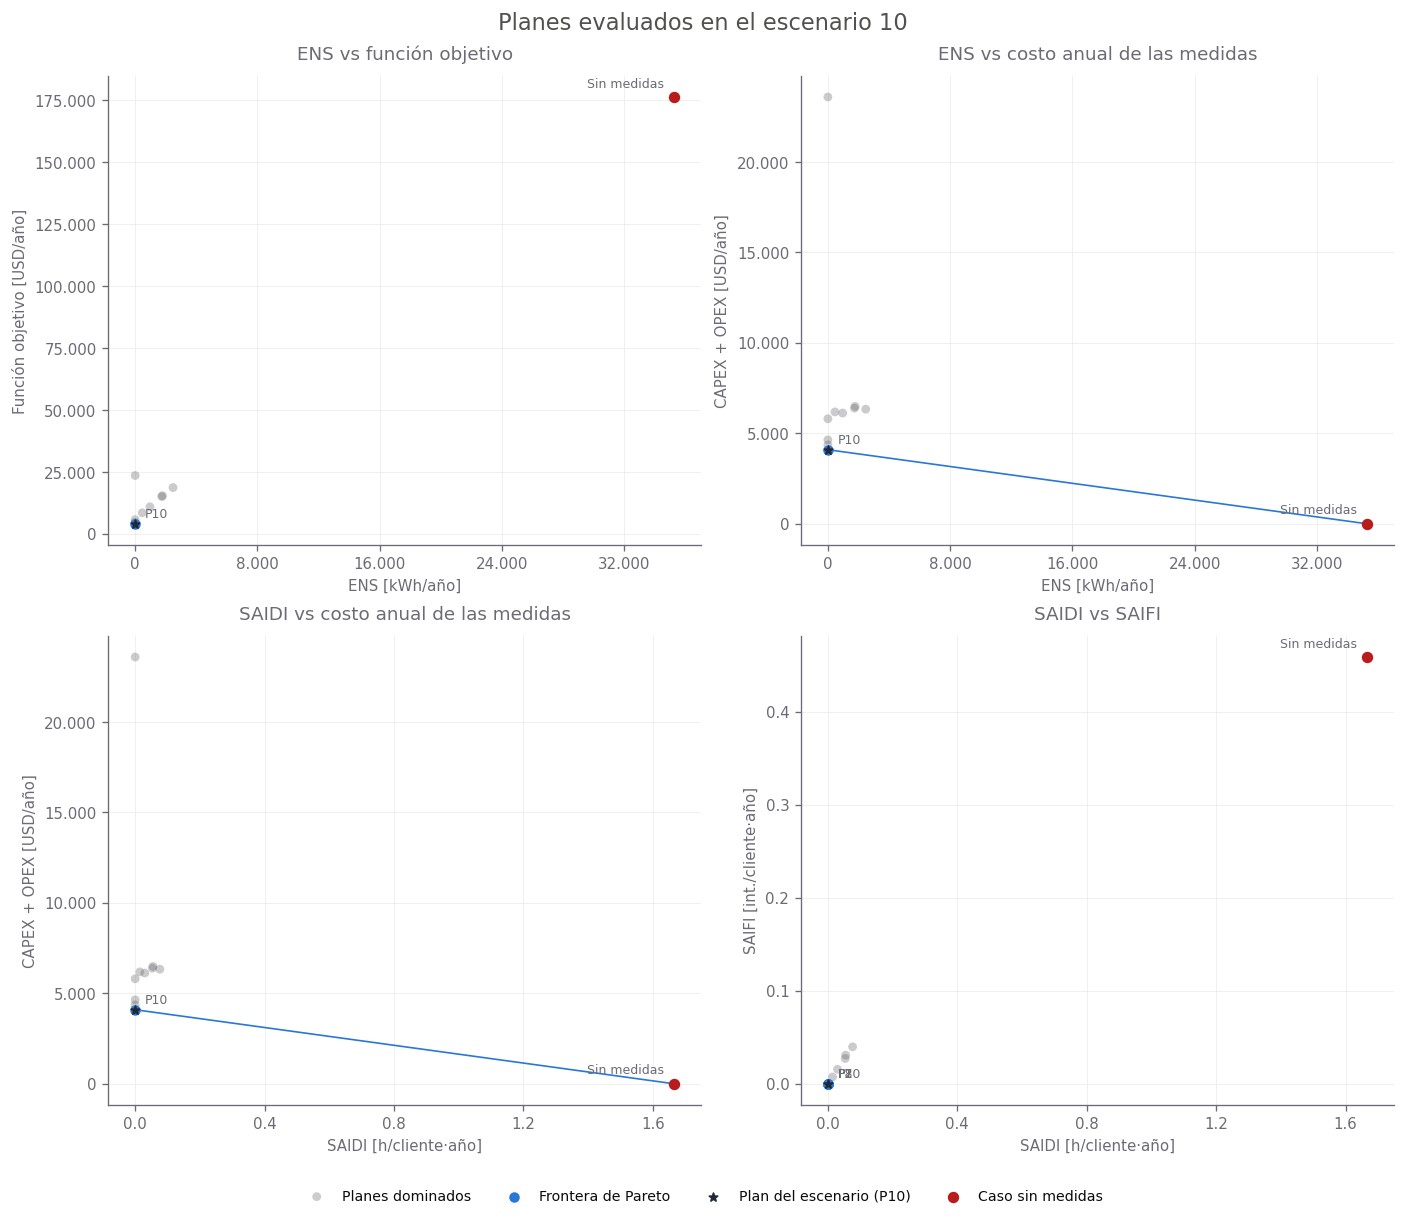

In [18]:
# ── 7.4 Trade-offs de un escenario ──────────────────────────────────────────
ESCENARIO_PARETO = ESCENARIOS  # None: una figura por cada escenario; o un número de ESC_PARETO

C_FRONTERA, C_DOMINADA, C_KNEE, C_DIAG = '#2a78d6', "#53565B", '#D55E00', '#1F2937'
C_BASE = '#B91C1C'
CON_BASE = True     # dibuja el caso sin medidas (costo 0) como referencia
PLAN_ADOPTADO = 'P10'   # plan adoptado en la elección; se rotula aunque quede dominado
fmt_miles = mpl.ticker.FuncFormatter(
    lambda v, _: f'{v:,.0f}'.replace(',', 'X').replace('.', ',').replace('X', '.'))
PANELES = [  # (x, y, título, etiqueta x, etiqueta y); el subtítulo dice qué se estudia en cada panel
     ('ens', 'func_obj', 'ENS vs función objetivo',
     'ENS [kWh/año]', 'Función objetivo [USD/año]'),
    ('ens', 'capex_opex', 'ENS vs costo anual de las medidas',
     'ENS [kWh/año]', 'CAPEX + OPEX [USD/año]'),
    ('saidi', 'capex_opex', 'SAIDI vs costo anual de las medidas',
     'SAIDI [h/cliente·año]', 'CAPEX + OPEX [USD/año]'),
    ('saidi', 'saifi', 'SAIDI vs SAIFI',
     'SAIDI [h/cliente·año]', 'SAIFI [int./cliente·año]'),
    # ('ens', 'func_obj', 'Energía no suministrada vs función objetivo',
    #  'ENS [kWh/año]', 'Función objetivo [USD/año]'),
    # ('saidi', 'ens', 'Energía no suministrada\nVerifica que ordena los planes igual que SAIDI',
    #  'SAIDI [h/cliente·año]', 'ENS [kWh/año]'),
]

def grilla(n):
    """(filas, columnas) para n paneles: 1×n hasta 2, 2×2 hasta 4, 2×3 hasta 6, 3×3 hasta 9."""
    assert 1 <= n <= 9, f'{n} paneles: máximo 9 por figura (3×3)'
    if n <= 2: return 1, n
    if n <= 4: return 2, 2
    if n <= 6: return 2, 3
    return 3, 3

def guardar_fig(fig, nombre):
    if 'guardar' in globals():      # función de la celda de estilo (tesis + presentación)
        guardar(fig, nombre)
    else:
        destino = globals().get('TESIS', APP / 'figuras_pareto')
        destino.mkdir(parents=True, exist_ok=True)
        for ext in ('pdf', 'png'):
            fig.savefig(destino / f'{nombre}.{ext}', dpi=300, bbox_inches='tight')
        print('→', destino / nombre)

def etiquetar(ax, df, x, y, frac=0.03):
    """Anota los planes; los que caen a menos de `frac` del rango se agrupan."""
    rx = max(np.ptp(df[x]), 1e-12); ry = max(np.ptp(df[y]), 1e-12)
    grupos = []
    for _, f in df.sort_values(x).iterrows():
        ax.annotate(f['plan'], (f[x], f[y]), textcoords='offset points', xytext=(6, 4), fontsize=7.5, color='#52514e')
        for g in grupos:
            if abs(f[x] - g[0][x]) < frac * rx and abs(f[y] - g[0][y]) < frac * ry:
                g.append(f); break
        else:
            grupos.append([f])
    # for g in grupos:
    #     ax.annotate(' / '.join(f['plan'] for f in g), (g[0][x], g[0][y]),
    #                 textcoords='offset points', xytext=(6, 4), fontsize=7.5, color='#52514e')
    

def dibujar(ax, e, x, y, etiquetas=True):
    # El caso base (sin medidas) entra en el cálculo del knee (7.3) y se dibuja
    # aparte como referencia si CON_BASE; no es un plan, así que no se mezcla
    # con la frontera ni con los dominados.
    # Dominancia calculada con los MISMOS ejes del panel (x, y), para que el color
    # (frontera / dominado) sea coherente con lo que se grafica. Solo entre los
    # planes: el caso sin medidas es una referencia y se dibuja aparte.
    fr, dom = frontera_pareto(PLANES[PLANES['escenario'] == e], [x, y])
    diag = PLANES[(PLANES['escenario'] == e) & PLANES['diagonal']].iloc[0]
    ax.scatter(dom[x], dom[y], s=28, color=C_DOMINADA, alpha=0.3, edgecolor='none',
               label='Planes dominados', zorder=2)
    ax.scatter(fr[x], fr[y], s=28, color=C_FRONTERA,
               label='Frontera de Pareto', zorder=2)
    ax.scatter(diag[x], diag[y], s=28, marker='*', color=C_DIAG, zorder=3,
               label=f'Plan del escenario ({diag["plan"]})')
    if CON_BASE:
        b = BASE.loc[e]
        ax.scatter(b[x], b[y], s=34, color=C_BASE, zorder=3, 
                   label='Caso sin medidas')
        ax.annotate('Sin medidas', (b[x], b[y]), textcoords='offset points',
                    xytext=(-6, 6), ha='right', fontsize=7.5, color=C_BASE)
    # Une con una línea continua los puntos de la frontera de cada panel; el caso sin medidas
    # se incluye solo cuando no está dominado en ese panel (costo cero). Con un solo punto no hay línea.
    union = PLANES[PLANES['escenario'] == e][[x, y]]
    if CON_BASE:
        union = pd.concat([union, BASE.loc[[e]][[x, y]]])
    union, _ = frontera_pareto(union, [x, y])
    union = union.sort_values(x)
    if len(union) > 1:
        ax.plot(union[x], union[y], color=C_FRONTERA, lw=1, zorder=1)
    # ax.scatter(knee[x], knee[y], s=170, facecolor='none', edgecolor=C_KNEE, lw=2,
    #            label=f'Knee point ({knee["plan"]})', zorder=4)
    if etiquetas:
        etiquetar(ax, fr, x, y)      # solo la frontera: los dominados se enciman
        # Plan adoptado: se rotula aunque quede dominado (si está en la frontera ya lo rotula etiquetar)
        adop = PLANES[(PLANES['escenario'] == e) & (PLANES['plan'] == PLAN_ADOPTADO)]
        if len(adop) and PLAN_ADOPTADO not in set(fr['plan']):
            ax.annotate(PLAN_ADOPTADO, (adop[x].iloc[0], adop[y].iloc[0]), textcoords='offset points',
                        xytext=(-6, -11), ha='right', fontsize=7.5, color='#52514e')
    for eje, col in ((ax.xaxis, x), (ax.yaxis, y)):
        if col in ('capex_opex', 'func_obj', 'ens'):
            eje.set_major_formatter(fmt_miles)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
    ax.grid(True, alpha=0.5); ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)


for e in sorted(ESC_PARETO if ESCENARIO_PARETO is None else ESCENARIO_PARETO, key=RANGO.get):
    # MEJORA: constrained_layout=True evita solapamientos de forma automática
    filas, cols = grilla(len(PANELES))
    fig, axes = plt.subplots(filas, cols, figsize=(5.8 * cols, 4.8 * filas), constrained_layout=True,
                             squeeze=False)
    axes = axes.ravel()
    for ax in axes[len(PANELES):]:       # celdas sobrantes de la grilla
        ax.set_visible(False)

    # MEJORA: Fondo de figura transparente
    fig.patch.set_facecolor('none')
    
    for ax, (x, y, titulo, xl, yl) in zip(axes, PANELES):
        dibujar(ax, e, x, y)
        ax.set(title=titulo, xlabel=xl, ylabel=yl)
        # MEJORA: Fondo de cada panel/eje transparente
        ax.patch.set_facecolor('none')
        
    b, knee = BASE.loc[e], RES[e][2]
    fig.suptitle(f'Planes evaluados en el escenario {RANGO[e]}',
                #  f'Caso base sin medidas: ENS {fmt_miles(b["ens"])} kWh, '
                #  f'SAIDI {b["saidi"]:.3f} h, SAIFI {b["saifi"]:.3f} int., función objetivo '
                #  f'{fmt_miles(b["func_obj"])} USD/año',
                 fontsize=13.5, color='#52514e')
                 
    h, l = axes[0].get_legend_handles_labels()
    
    # MEJORA: Leyenda ubicada de forma limpia usando constrained_layout
    fig.legend(h, l, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.05))
    
    guardar_fig(fig, f'pareto_planes_esc_{RANGO[e]:02d}')
    plt.show()

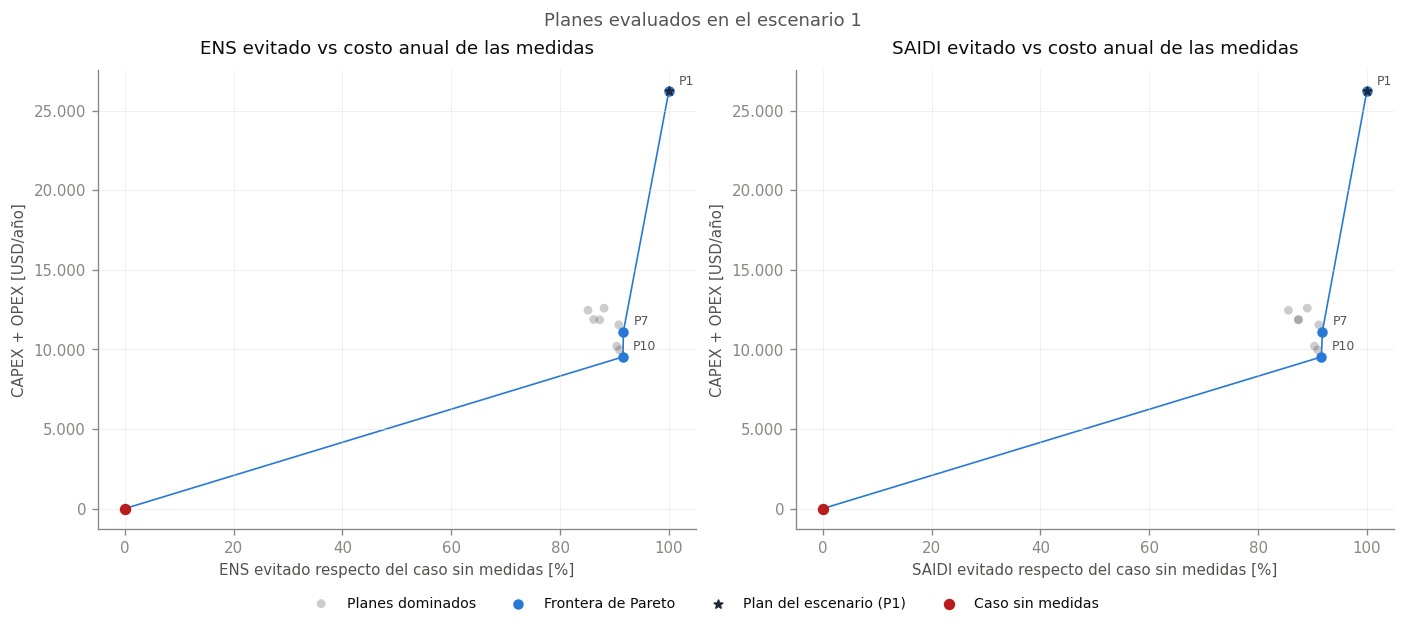

In [19]:
# ── Prueba: ejes en % de reducción respecto del caso sin medidas (solo los dos paneles de costo) ──
# Celda de prueba: no guarda nada en Figuras/. Cambiar PRUEBA_ESC por ESC_PARETO para ver los 10 escenarios.
PRUEBA_ESC = [ESC_PARETO[0]]

for e in PRUEBA_ESC:
    b = BASE.loc[e]
    P = PLANES[PLANES['escenario'] == e]
    diag = P[P['diagonal']].iloc[0]
    fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.8), constrained_layout=True)
    for ax, (col, nombre) in zip(axes, (('ens', 'ENS'), ('saidi', 'SAIDI'))):
        ev = lambda v: 100 * (1 - v / b[col])                    # % evitado respecto del caso sin medidas
        fr, dom = frontera_pareto(P, [col, 'capex_opex'])
        union, _ = frontera_pareto(pd.concat([P[[col, 'capex_opex']], BASE.loc[[e]][[col, 'capex_opex']]]),
                                   [col, 'capex_opex'])
        union = union.sort_values(col)
        ax.plot(ev(union[col]), union['capex_opex'], color=C_FRONTERA, lw=1, zorder=1)
        ax.scatter(ev(dom[col]), dom['capex_opex'], s=28, color=C_DOMINADA, alpha=0.3,
                   edgecolor='none', label='Planes dominados', zorder=2)
        ax.scatter(ev(fr[col]), fr['capex_opex'], s=28, color=C_FRONTERA,
                   label='Frontera de Pareto', zorder=2)
        ax.scatter(ev(diag[col]), diag['capex_opex'], s=28, marker='*', color=C_DIAG, zorder=3,
                   label=f'Plan del escenario ({diag["plan"]})')
        ax.scatter(0, b['capex_opex'], s=34, color=C_BASE, zorder=3, label='Caso sin medidas')
        for _, r in fr.iterrows():
            ax.annotate(r['plan'], (ev(r[col]), r['capex_opex']), textcoords='offset points',
                        xytext=(6, 4), fontsize=7.5, color='#555555')
        ax.set(title=f'{nombre} evitado vs costo anual de las medidas',
               xlabel=f'{nombre} evitado respecto del caso sin medidas [%]',
               ylabel='CAPEX + OPEX [USD/año]')
        ax.yaxis.set_major_formatter(fmt_miles)
        ax.grid(True, alpha=0.5)
        ax.spines[['top', 'right']].set_visible(False)
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.07))
    fig.suptitle(f'Planes evaluados en el escenario {RANGO[e]}', color='#555555')
    plt.show()

In [20]:
# ── 7.5 Costo vs ENS en todos los escenarios ────────────────────────────
# x, y = OBJETIVOS_PARETO
# n = len(ESC_PARETO)
# fig, axes = plt.subplots(2, int(np.ceil(n / 2)), figsize=(16, 6.6), sharex=True)
# for ax, e in zip(axes.flat, ESC_PARETO):
#     dibujar(ax, e, x, y, etiquetas=False)
#     knee = RES[e][2]
#     ax.annotate(knee['plan'], (knee[x], knee[y]), textcoords='offset points', xytext=(8, 6),
#                 fontsize=8, color=C_KNEE)
#     ax.set_title(f'Escenario {e} · base {fmt_miles(BASE.loc[e, "ens"])} kWh', fontsize=10)
# for ax in axes.flat[n:]:
#     ax.set_visible(False)
# for ax in axes[-1]:
#     ax.set_xlabel('CAPEX + OPEX [USD/año]')
# for ax in axes[:, 0]:
#     ax.set_ylabel('ENS [kWh/año]')
# fig.legend([mpl.lines.Line2D([], [], marker='o', ls='', color=C_DOMINADA, alpha=0.5),
#             mpl.lines.Line2D([], [], marker='o', ls='', color=C_FRONTERA),
#             mpl.lines.Line2D([], [], marker='*', ls='', ms=10, color=C_DIAG),
#             mpl.lines.Line2D([], [], marker='o', ls='', ms=11, mfc='none', mec=C_KNEE, mew=2)],
#            ['Planes dominados', 'Frontera de Pareto', 'Plan del escenario', 'Knee point'],
#            loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.01))
# fig.tight_layout(rect=(0, 0.05, 1, 1))
# guardar_fig(fig, 'pareto_planes_por_escenario')
# plt.show()

## 8. Frontera de Pareto de los planes promediados sobre los escenarios

Cada plan `P<k>` (óptimo de la librería completa para el escenario de rango `k`) se evalúa en los 10 escenarios de la matriz plan × escenario. Aquí se promedian de forma equiprobable las métricas de cada plan sobre los 10 escenarios, de modo que quedan 10 puntos, uno por plan, y la frontera responde a qué plan conviene si no se sabe cuál escenario ocurrirá. Los paneles son los de `PANELES` en 7.4, con la dominancia calculada con los mismos dos ejes de cada panel. El caso sin medidas promedio se dibuja como referencia.

In [21]:
# ── 8.1 Promedio de cada plan sobre los escenarios ──────────────────────────
# Promedio equiprobable de capex_opex, func_obj, ens, saidi y saifi de cada plan en los
# 10 escenarios (misma ponderación que la ENS esperada de las secciones anteriores).
PROM = PLANES.groupby('plan')[METRICAS].mean().reset_index()
PROM = PROM.sort_values('plan', key=lambda s: s.str[1:].astype(int)).reset_index(drop=True)
BASE_PROM = BASE[METRICAS].mean()
assert (PLANES.groupby('plan')['escenario'].nunique() == len(ESC_PARETO)).all()

# Frontera con costo y ENS promedio, como la tabla de 7.3 (sin el caso sin medidas).
fr_prom, _ = frontera_pareto(PROM, OBJETIVOS_PARETO)
TABLA_PROM = PROM.assign(
    **{f'Δ{m.upper()} %': 100 * (1 - PROM[m] / BASE_PROM[m]) for m in ('ens', 'saidi', 'saifi')},
    En_frontera=PROM['plan'].isin(fr_prom['plan'])).set_index('plan')
print('Caso sin medidas (promedio):', BASE_PROM.round(3).to_dict())
print('En la frontera', OBJETIVOS_PARETO, ':', ', '.join(fr_prom['plan']))
TABLA_PROM.round(3)

Caso sin medidas (promedio): {'capex_opex': 0.0, 'func_obj': 219618.357, 'ens': 43923.671, 'saidi': 1.894, 'saifi': 0.574}
En la frontera ['capex_opex', 'ens'] : P10, P7, P1


,capex_opex,func_obj,ens,saidi,saifi,ΔENS %,ΔSAIDI %,ΔSAIFI %,En_frontera
plan,,,,,,,,,
P1,25151.568,27187.777,407.242,0.017,0.007,99.073,99.086,98.725,True
P2,6654.123,15503.257,1769.827,0.071,0.024,95.971,96.232,95.804,False
P3,6995.796,16231.629,1847.167,0.073,0.025,95.795,96.149,95.635,False
P4,7370.138,19279.952,2381.963,0.092,0.036,94.577,95.122,93.688,False
P5,7280.690,17970.271,2137.916,0.085,0.031,95.133,95.523,94.605,False
P6,7776.055,20501.705,2545.130,0.098,0.040,94.206,94.802,92.964,False
P7,6938.301,15135.442,1639.428,0.066,0.021,96.268,96.507,96.308,True
P8,6676.734,15891.313,1842.916,0.074,0.027,95.804,96.078,95.211,False
P9,7388.653,19914.963,2505.262,0.095,0.037,94.296,94.999,93.512,False


→ pareto_planes_promedio


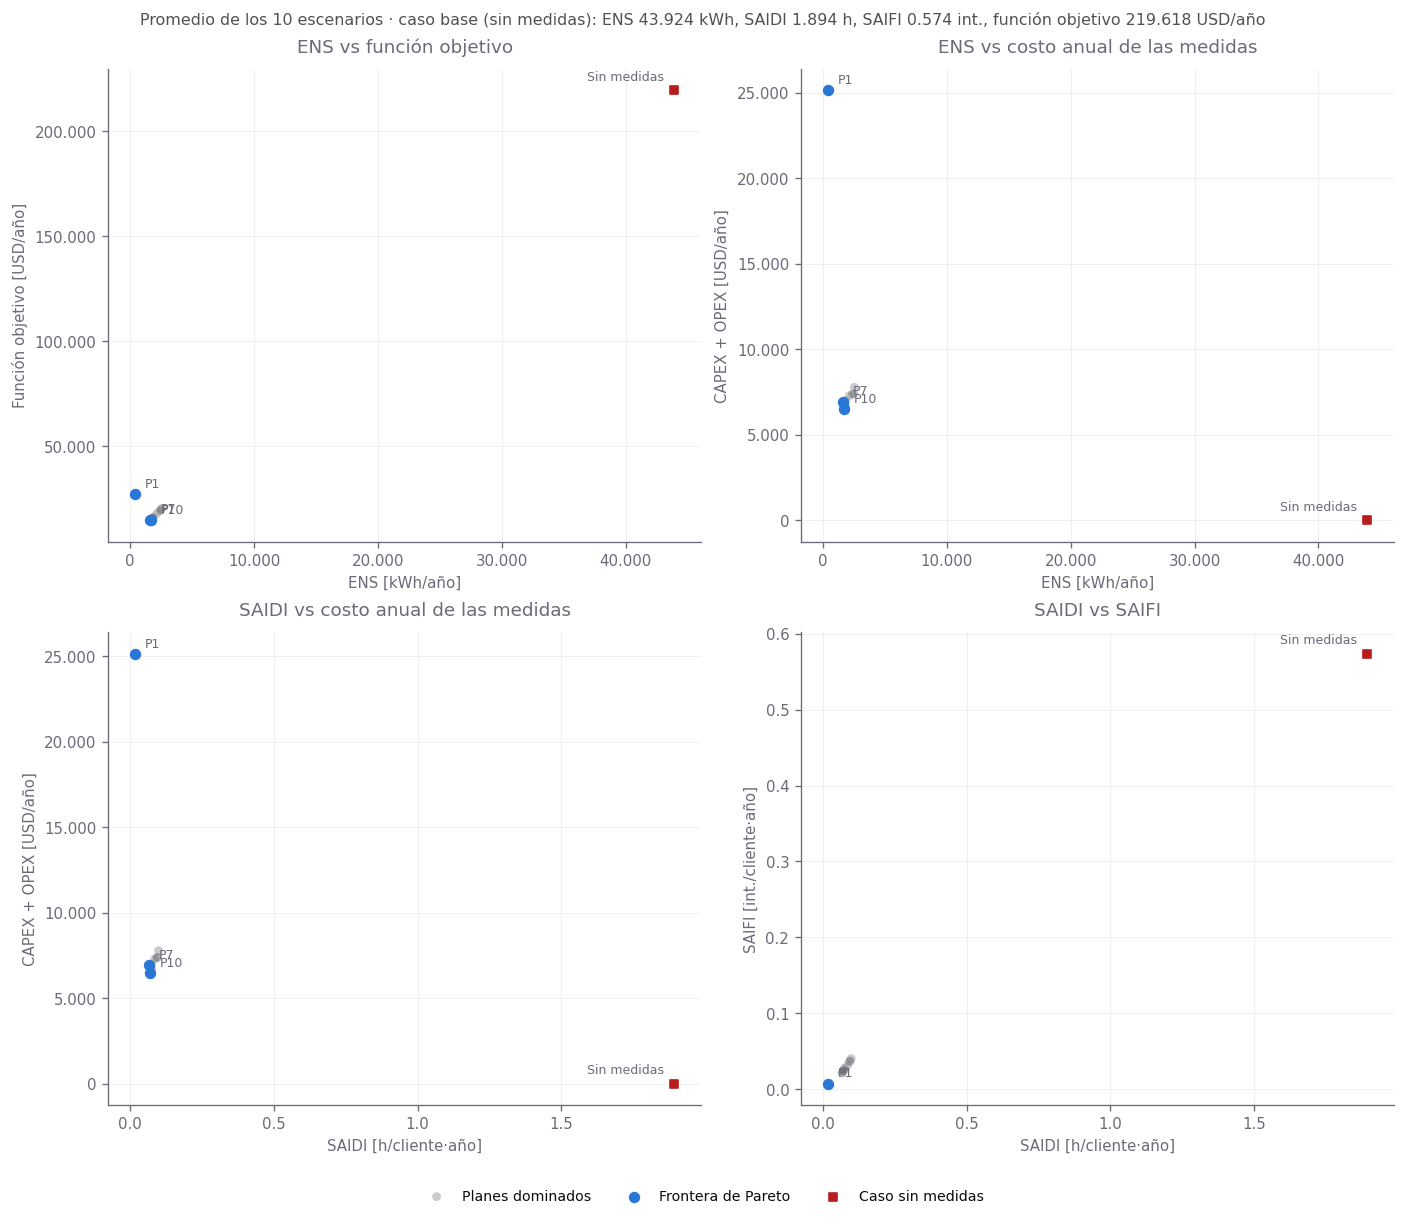

In [22]:
# ── 8.2 Trade-offs con los planes promediados ───────────────────────────────
def dibujar_prom(ax, x, y):
    # Dominancia calculada con los mismos ejes del panel, entre los 10 planes promedio.
    fr, dom = frontera_pareto(PROM, [x, y])
    ax.scatter(dom[x], dom[y], s=28, color=C_DOMINADA, alpha=0.3, edgecolor='none',
               label='Planes dominados', zorder=2)
    ax.scatter(fr[x], fr[y], s=34, color=C_FRONTERA, label='Frontera de Pareto', zorder=3)
    if CON_BASE:
        ax.scatter(BASE_PROM[x], BASE_PROM[y], s=28, marker='s', color=C_BASE, zorder=5,
                   label='Caso sin medidas')
        ax.annotate('Sin medidas', (BASE_PROM[x], BASE_PROM[y]), textcoords='offset points',
                    xytext=(-6, 6), ha='right', fontsize=7.5, color=C_BASE)
    etiquetar(ax, fr, x, y)           # solo la frontera: los 10 planes quedan muy juntos
    for eje, col in ((ax.xaxis, x), (ax.yaxis, y)):
        if col in ('capex_opex', 'func_obj', 'ens'):
            eje.set_major_formatter(fmt_miles)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
    ax.grid(True, alpha=0.5); ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

filas, cols = grilla(len(PANELES))
fig, axes = plt.subplots(filas, cols, figsize=(5.8 * cols, 4.8 * filas), constrained_layout=True,
                         squeeze=False)
axes = axes.ravel()
for ax in axes[len(PANELES):]:
    ax.set_visible(False)
fig.patch.set_facecolor('none')
for ax, (x, y, titulo, xl, yl) in zip(axes, PANELES):
    dibujar_prom(ax, x, y)
    ax.set(title=titulo, xlabel=xl, ylabel=yl)
    ax.patch.set_facecolor('none')
b = BASE_PROM
fig.suptitle(f'Promedio de los {len(ESC_PARETO)} escenarios · caso base (sin medidas): '
             f'ENS {fmt_miles(b["ens"])} kWh, SAIDI {b["saidi"]:.3f} h, SAIFI {b["saifi"]:.3f} int., '
             f'función objetivo {fmt_miles(b["func_obj"])} USD/año', fontsize=9.5, color='#52514e')
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.05))
guardar_fig(fig, 'pareto_planes_promedio')
plt.show()

## 9. Evaluación comparativa con el plan adoptado P10

Las figuras de ENS por escenario, por zona y por hora de las secciones 3 y 4 muestran el plan de cada escenario (la cartera resuelta en cada uno, cota con información perfecta). Aquí se rehacen con el plan adoptado `P10` evaluado con su inversión fija en los 10 escenarios (`plan_fijo/<cartera>/plan_esc_<id>/esc_<e>.npz`), y el plan de cada escenario queda como referencia. Salidas: `ens_pareada_p10`, `ens_zona_p10`, `ens_horaria_p10`.

Plan adoptado: P10 = plan del escenario

 15
ENS media · base 43.924 · P10 1.683 · plan propio 1.144 kWh
→ ens_pareada_p10


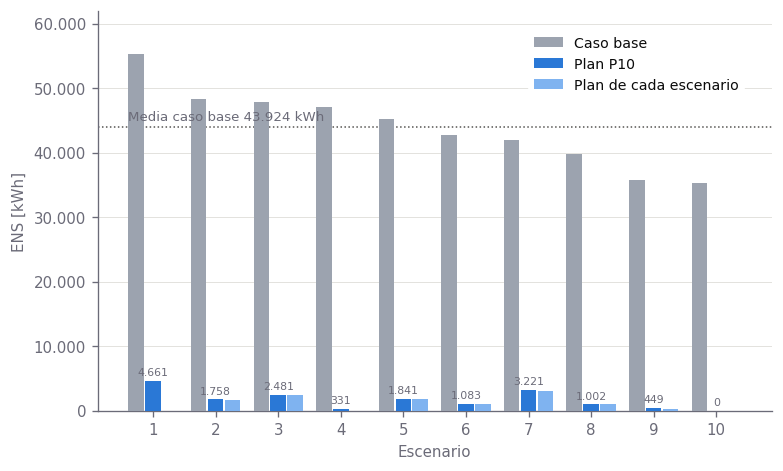

,Caso base,Plan P10,Plan de cada escenario,Reducción P10 %,Reducción plan propio %
1,55279.4,4660.6,0.0,91.6,100.0
2,48279.8,1758.2,1715.8,96.4,96.4
3,47802.4,2481.4,2481.4,94.8,94.8
4,47044.5,330.6,0.0,99.3,100.0
5,45250.6,1840.9,1840.9,95.9,95.9
6,42723.5,1083.3,1065.1,97.5,97.5
7,41977.2,3221.4,3085.0,92.3,92.7
8,39775.2,1001.7,991.9,97.5,97.5
9,35835.9,448.5,257.0,98.7,99.3
10,35268.1,0.0,0.0,100.0,100.0


In [20]:
# ── 9.1 Plan P10 por escenario ──────────────────────────────────────────────
# P<k> es el plan optimizado para el escenario de rango k (7.1); P10 = el de menor ENS del caso base.
DIR_MATRIZ = matrices[0].parent
ELEGIDO = ESC_PARETO[-1]
assert RANGO[ELEGIDO] == 10
larga_v = pd.read_csv(DIR_MATRIZ / 'matriz_larga.csv')
P10 = larga_v[larga_v['plan'] == ELEGIDO].set_index('escenario').loc[ESC_PARETO]
com_v = pd.read_csv(DIR_TANDA / 'resumen_combinadas.csv')
propio = com_v[com_v['combinacion'] == CARTERA].set_index('escenario')['ens']

par10 = pd.DataFrame({'Caso base': BASE.loc[ESC_PARETO, 'ens'], 'Plan P10': P10['ens'],
                      'Plan de cada escenario': propio.loc[ESC_PARETO]})
par10['Reducción P10 %'] = 100 * (1 - par10['Plan P10'] / par10['Caso base'])
par10['Reducción plan propio %'] = 100 * (1 - par10['Plan de cada escenario'] / par10['Caso base'])
par10.index = [RANGO[e] for e in par10.index]             # escenario 1 = mayor ENS del caso base
print('Plan adoptado: P10 = plan del escenario', ELEGIDO)
print('ENS media · base %s · P10 %s · plan propio %s kWh' % tuple(miles(par10[c].mean()) for c in
      ('Caso base', 'Plan P10', 'Plan de cada escenario')))

fig, ax = plt.subplots(figsize=(6.6, 4))
x = np.arange(len(par10)); w = 0.27
ax.bar(x - w, par10['Caso base'], w * 0.92, color=COLOR_BASE, label='Caso base', zorder=3)
ax.bar(x, par10['Plan P10'], w * 0.92, color=COLOR_CARTERA, label='Plan P10', zorder=3)
ax.bar(x + w, par10['Plan de cada escenario'], w * 0.92, color='#7FB3F0', label='Plan de cada escenario', zorder=3)
for i, c in enumerate(par10['Plan P10']):
    ax.annotate(miles(c), (x[i], c), textcoords='offset points', xytext=(0, 3),
                ha='center', fontsize=6.5, color=TINTA_2)
ax.axhline(par10['Caso base'].mean(), color=TINTA_2, lw=0.9, ls=':')
ax.annotate(f"Media caso base {miles(par10['Caso base'].mean())} kWh", (x[0] - 0.4, par10['Caso base'].mean()),
            textcoords='offset points', xytext=(0, 4), fontsize=8, color=TINTA_2)
ax.set_xticks(x, [str(k) for k in par10.index])
ax.set(xlabel='Escenario', ylabel='ENS [kWh]')
ax.yaxis.set_major_formatter(EJE_MILES)
ax.grid(True, axis='y'); ax.set_axisbelow(True); ax.margins(y=0.12)
ax.legend(loc='upper right', bbox_to_anchor=(0.97, 0.97))
fig.tight_layout()
guardar(fig, 'ens_pareada_p10')
plt.show()
par10.round(1)

In [7]:
# ── 9.2 ENS por zona y horaria con P10 ──────────────────────────────────────
# Mismas figuras que la app (graficos_valor_esperado.figuras_ens), como en la sección 3.
import barrido_vista as BV
from graficos_valor_esperado import promediar_ens, figuras_ens

red_v = BV.P._cargar('red.pkl')
bases_v = [BV.P.base_dir('sec-0-2-9-10') / f'esc_{e:03d}.npz' for e in ESC_PARETO]
rutas_v = [DIR_MATRIZ / f'plan_esc_{ELEGIDO:03d}' / f'esc_{e:03d}.npz' for e in ESC_PARETO]
horario10, zonal10 = promediar_ens(rutas_v, bases_v, red_v['BUSES'], red_v['bus_zone'], 8760)
assert np.isclose(zonal10['Caso base'].sum(), BASE['ens'].mean(), rtol=1e-6)
assert np.isclose(zonal10['Con medida'].sum(), P10['ens'].mean(), rtol=1e-6)

fig_zona10, fig_hora10 = figuras_ens(horario10, zonal10, 'Plan P10')
for fig in (fig_zona10, fig_hora10):
    fig.update_layout(paper_bgcolor='white', plot_bgcolor='white', margin=dict(l=170),
                      legend=dict(orientation='h', x=0, y=-0.22, font=dict(size=25),
                                  itemwidth=40, entrywidthmode='pixels', entrywidth=380))
    fig.update_yaxes(title_standoff=25)
fig_hora10.update_layout(legend=dict(y=-0.3))
fig_hora10.data[1].line.color = '#56B4E9'   # celeste, como la figura de la app
for fig, nombre in ((fig_zona10, 'ens_zona_p10'), (fig_hora10, 'ens_horaria_p10')):
    for ext in ('pdf', 'png'):
        fig.write_image(TESIS / f'{nombre}.{ext}', scale=2)
    print('→', nombre)
    fig.show()

pico10 = horario10.loc[horario10['Caso base'].idxmax()]
print('Pico caso base: hora', int(pico10['Hora']), '·', miles(pico10['Caso base']), 'kWh · P10 en esa hora',
      miles(pico10['Con medida'], 1), 'kWh')
print('Horas con ENS > 1 kWh · base', int((horario10['Caso base'] > 1).sum()),
      '· P10', int((horario10['Con medida'] > 1).sum()))
print('Máximo horario P10:', miles(horario10['Con medida'].max(), 1), 'kWh en la hora',
      int(horario10.loc[horario10['Con medida'].idxmax(), 'Hora']))
print('Participación de cada zona en la ENS con P10 [%]:',
      np.round(100 * zonal10['Con medida'] / zonal10['Con medida'].sum(), 1).tolist())
zonal10.round(1)

2026-10-29 02:47:41.243 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:47:41.253 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:47:41.253 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:47:41.259 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:47:41.264 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 02:47:41.264 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


→ ens_zona_p10


→ ens_horaria_p10


Pico caso base: hora 5105 · 2.383 kWh · P10 en esa hora 128,7 kWh
Horas con ENS > 1 kWh · base 165 · P10 42
Máximo horario P10: 128,7 kWh en la hora 5105
Participación de cada zona en la ENS con P10 [%]: [5.3, 0.8, 93.9]


,Zona,Caso base,Con medida
0,Zona 1,8400.0,89.9
1,Zona 2,9043.1,12.7
2,Zona 3,26480.6,1580.0


In [ ]:
# ── 9.3 Cascada: del caso base a la ENS residual con el plan de cada escenario ──
# El abatimiento conjunto de la librería completa (menor que la suma de los individuales) se reparte entre las
# medidas activas en proporción a su abatimiento individual. Es un reparto convencional, no un efecto marginal:
# el orden y la interacción entre medidas no se pueden separar sin resolver combinaciones intermedias.
caso = CARTERA
fila_c = comb[comb['_caso'] == caso].iloc[0]
aporte = {m: np.mean([max(float(D_IND.loc[(m, e), 'd_ens']), 0.0) if m in ACTIVA[(caso, e)] else 0.0
                      for e in ESCENARIOS])
          for m in ORDEN_MEDIDAS}
aporte = {m: v for m, v in aporte.items() if v > 1}
suma = sum(aporte.values())
ens_base_c = float(ESPERADOS['ens_base'].iloc[0])
ens_res_c = float(fila_c['ens'])
conjunto = ens_base_c - ens_res_c
reparto = {m: conjunto * v / suma for m, v in aporte.items()}

fig, ax = plt.subplots(figsize=(6.6, 3.8))
y = ens_base_c
ax.bar(0, y, 0.7, color=COLOR_BASE, zorder=3)
ax.annotate(miles(y), (0, y), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=7.5, color=TINTA_2)
nombres = ['Caso base']
for i, (m, v) in enumerate(reparto.items(), 1):
    ax.bar(i, v, 0.7, bottom=y - v, color=COLOR_MEDIDA[m], zorder=3)
    ax.annotate('−' + miles(v), (i, y), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=7.5, color=TINTA_2)
    y -= v
    nombres.append(NOMBRE_MEDIDA[m])
ax.bar(len(nombres), ens_res_c, 0.7, color=COLOR_CARTERA, zorder=3)
ax.annotate(miles(ens_res_c), (len(nombres), ens_res_c), xytext=(0, 3), textcoords='offset points',
            ha='center', fontsize=7.5, color=TINTA_2)
nombres.append('ENS residual')
ax.set_xticks(range(len(nombres)), nombres, fontsize=7.5, rotation=35, ha='right')
ax.set_ylabel('ENS [kWh]'); ax.yaxis.set_major_formatter(EJE_MILES)
ax.grid(True, axis='y'); ax.set_axisbelow(True); ax.margins(y=0.1)
fig.tight_layout()
guardar(fig, 'cascada_ens')
plt.show()
print('Suma de abatimientos individuales de las medidas activas: %s kWh · abatimiento conjunto: %s kWh'
      % (miles(suma), miles(conjunto)))
pd.Series(reparto).rename(index=NOMBRE_MEDIDA).round(0)

## 10. Pareto de los planes en dos eventos (20 planes × 20 escenarios)

Salida de `run_plan_fijo.py` con `--salida-nombre 2eventos_sin_inv_tie` (evento 2024) y `todas_2eventos` (evento 2020, combinadas sin `inv_tie`, como las del 2024): los **10 planes del caso 2024** (esta tanda) y los **10 planes del evento 2020** (semilla 43, los 10 escenarios de mayor ENS, mismos supuestos) se fijan y se evalúan en los **20 escenarios** (10 de cada evento). Los planes `P1`–`P10` son los óptimos de los escenarios de rango 1 a 10 del evento 2024 (los mismos de la sección 7); `P11`–`P20`, los del evento 2020 (`P11` = escenario de rango 1 de ese evento). Los rangos se numeran por ENS del caso base dentro de cada evento (1 = mayor ENS).

En cada escenario se comparan los 20 planes (círculo: plan del mismo evento; triángulo: plan del otro evento). Ejes, dominancia y estilo son los de la sección 7. El `capex_opex` se calcula igual que en 7.1; la constante del E4 (distinta en cada evento) se resta con el mínimo del sobrecosto de cada evento (el plan sin sobrecosto DG queda en 0, como en la tanda 2024). La sección es autónoma: basta ejecutar sus celdas en orden desde `datos/` (si ya corriste el estilo del inicio y 7.2, reutiliza `frontera_pareto` y el estilo). Las figuras van a `figuras_pareto_2eventos/` (no a la carpeta de la tesis).

In [ ]:
# ── 10.0 Dependencias (la sección corre sola; si ya ejecutaste el inicio y 7.2 se reutilizan) ──
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

if 'APP' not in globals():
    APP = Path.cwd()                          # .../caso_validacion/datos
if 'TINTA_2' not in globals():
    TINTA_2 = '#52514e'
if 'fmt_miles' not in globals():
    fmt_miles = mpl.ticker.FuncFormatter(
        lambda v, _: f'{v:,.0f}'.replace(',', 'X').replace('.', ',').replace('X', '.'))
C_FRONTERA, C_DOMINADA, C_DIAG, C_BASE = '#2a78d6', '#53565B', '#1F2937', '#B91C1C'

if 'frontera_pareto' not in globals():
    def frontera_pareto(df, objetivos, rtol=1e-6):
        """No dominadas / dominadas (todos los objetivos se minimizan); igual que 7.2."""
        X = df[list(objetivos)].to_numpy(float)
        tol = rtol * np.maximum(np.ptp(X, axis=0), 1e-12)
        no_dom = np.ones(len(X), bool)
        for ini in range(0, len(X), 512):
            Xi = X[ini:ini + 512, None, :]
            no_peor = (X[None] <= Xi + tol).all(-1)
            mejor = (X[None] < Xi - tol).any(-1)
            no_dom[ini:ini + 512] = ~(no_peor & mejor).any(1)
        return df[no_dom].sort_values(list(objetivos)), df[~no_dom]

# ── 10.1 Carga: 20 planes × 20 escenarios ─────────────────────────────────
import os
_cwd = os.getcwd()
import pipeline as _pipe                      # al importarlo cambia el cwd
os.chdir(_cwd)

# red.pkl y costos.pkl no están en validacion_2020_s43: son los mismos del evento 2024 (misma red CIGRE y costos)
_cargar_orig = _pipe._cargar
def _cargar_con_respaldo(nombre, art_dir=None):
    ruta = Path(art_dir or _pipe.ART_DIR) / nombre
    if not ruta.exists():
        art_dir = APP / 'artefactos' / 'validacion'
    return _cargar_orig(nombre, art_dir)
_pipe._cargar = _cargar_con_respaldo

VARIANTE_2E = 'sec-0-2-9-10'
EVENTOS_2E = {
    '2024': (APP / 'artefactos' / 'validacion',
             APP / 'artefactos' / 'validacion' / 'barrido' / 'sec-0-2-9-10 severo' / 'plan_fijo' / '2eventos_sin_inv_tie'),
    '2020': (APP / 'artefactos' / 'validacion_2020_s43',
             APP / 'artefactos' / 'validacion_2020_s43' / 'barrido' / 'sec-0-2-9-10 2020 semilla43 sin_inv_tie'
             / 'plan_fijo' / 'todas_2eventos'),
}
OTRO_EV = {'2024': '2020', '2020': '2024'}

filas, base = [], []
for ev, (art, dirm) in EVENTOS_2E.items():
    L = pd.read_csv(dirm / 'matriz_larga.csv')
    sob = L['objetivo'] - L['cst_objetivo_plan']
    sob = sob - sob.min()                     # quita la constante del E4 de este evento
    cx = L['cst_capex_anual'] + L['cst_opex_anual'] + sob
    assert (cx - L['cst_costo_total']).min() > -1e-3, ev   # el sobrecosto DG solo suma
    # id < 100: plan del propio evento; id >= 100: plan del otro evento (id - 100 = su escenario)
    propio = L['plan'] < 100
    filas.append(pd.DataFrame({
        'ev_esc': ev, 'esc': L['escenario'].astype(int),
        'ev_plan': np.where(propio, ev, OTRO_EV[ev]),
        'id_plan': np.where(propio, L['plan'], L['plan'] - 100).astype(int),
        'capex_opex': cx, 'func_obj': cx + L['cst_costo_ens_estr'],
        'ens': L['ens'], 'saidi': L['saidi'], 'saifi': L['saifi']}))
    assert L['plan'].nunique() == 20 and L['escenario'].nunique() == 10, (ev, L.shape)
    for e in sorted(L['escenario'].unique()):
        b = _pipe.indicadores_baseline(int(e), VARIANTE_2E, art_dir=art, guardar_cache=False)
        base.append({'ev_esc': ev, 'esc': int(e), 'plan': 'Caso base', 'capex_opex': 0.0,
                     'func_obj': b['costo_ens'], 'ens': b['ens'], 'saidi': b['saidi'], 'saifi': b['saifi']})

PLANES2 = pd.concat(filas, ignore_index=True)
BASE2 = pd.DataFrame(base).set_index(['ev_esc', 'esc'])

# Rango dentro de cada evento: 1 = mayor ENS del caso base.
RANGO2 = {}
for ev in EVENTOS_2E:
    b = BASE2.loc[ev]['ens'].sort_values(ascending=False, kind='stable')
    RANGO2.update({(ev, int(e)): k for k, e in enumerate(b.index, 1)})
# P1-P10: planes del evento 2024 (como en 7); P11-P20: planes del evento 2020, cada grupo por rango de ENS.
DESPLAZA_2E = {'2024': 0, '2020': 10}
PLANES2['plan'] = [f'P{DESPLAZA_2E[ev] + RANGO2[(ev, i)]}' for ev, i in zip(PLANES2['ev_plan'], PLANES2['id_plan'])]
PLANES2['mismo_evento'] = PLANES2['ev_plan'] == PLANES2['ev_esc']
NUM_2E = {k: DESPLAZA_2E[k[0]] + RANGO2[k] for k in BASE2.index}   # escenario 1-20 (1-10: evento 2024; 11-20: evento 2020)
PLANES2['diagonal'] = PLANES2['mismo_evento'] & (PLANES2['id_plan'] == PLANES2['esc'])
assert PLANES2.groupby(['ev_esc', 'esc']).size().eq(20).all() and PLANES2[['capex_opex', 'ens']].notna().all().all()
print(PLANES2['plan'].nunique(), 'planes ×', len(BASE2), 'escenarios')
BASE2.assign(rango=[RANGO2[k] for k in BASE2.index]).round(1)

In [ ]:
# ── 10.2 Frontera por escenario (capex_opex vs ENS) ────────────────────────
filas = []
for (ev, e), b in BASE2.iterrows():
    sub = PLANES2[(PLANES2['ev_esc'] == ev) & (PLANES2['esc'] == e)]
    fr, _ = frontera_pareto(sub, ['capex_opex', 'ens'])
    d = sub[sub['diagonal']].iloc[0]
    filas.append({'Evento': ev, 'Escenario': RANGO2[(ev, e)], 'Id': e, 'Plan propio': d['plan'],
                  'En frontera': d['plan'] in set(fr['plan']), 'N frontera': len(fr),
                  'Frontera': ', '.join(fr['plan']),
                  'Del otro evento': int((~fr['mismo_evento']).sum())})
RESUMEN_2E = pd.DataFrame(filas).set_index(['Evento', 'Escenario']).sort_index()
print('Veces que cada plan está en la frontera:',
      pd.Series(', '.join(RESUMEN_2E['Frontera']).split(', ')).value_counts().to_dict())
RESUMEN_2E

In [ ]:
# ── 10.3 Una figura por escenario (20) ─────────────────────────────────────
from matplotlib.lines import Line2D
PARETO_2E = APP / 'figuras_pareto_2eventos'
PARETO_2E.mkdir(exist_ok=True)

def etiquetar2(ax, df, x, y):
    for _, f in df.sort_values(x).iterrows():
        ax.annotate(f['plan'], (f[x], f[y]), textcoords='offset points', xytext=(6, 4),
                    fontsize=7.5, color='#52514e')

def dibujar2(ax, ev, e, x, y):
    sub = PLANES2[(PLANES2['ev_esc'] == ev) & (PLANES2['esc'] == e)]
    fr, dom = frontera_pareto(sub, [x, y])
    for df, color, alpha in ((dom, C_DOMINADA, 0.3), (fr, C_FRONTERA, 1.0)):
        for mismo, marca in ((True, 'o'), (False, '^')):
            d = df[df['mismo_evento'] == mismo]
            ax.scatter(d[x], d[y], s=30, marker=marca, color=color, alpha=alpha, edgecolor='none', zorder=2)
    dg = sub[sub['diagonal']].iloc[0]
    ax.scatter(dg[x], dg[y], s=40, marker='*', color=C_DIAG, zorder=3)
    b = BASE2.loc[(ev, e)]
    ax.scatter(b[x], b[y], s=34, color=C_BASE, zorder=3)
    ax.annotate('Sin medidas', (b[x], b[y]), textcoords='offset points', xytext=(-6, 6),
                ha='right', fontsize=7.5, color=C_BASE)
    union, _ = frontera_pareto(pd.concat([sub[[x, y]], BASE2.loc[[(ev, e)]][[x, y]]]), [x, y])
    union = union.sort_values(x)
    if len(union) > 1:
        ax.plot(union[x], union[y], color=C_FRONTERA, lw=1, zorder=1)
    etiquetar2(ax, fr, x, y)
    for eje, col in ((ax.xaxis, x), (ax.yaxis, y)):
        if col in ('capex_opex', 'func_obj', 'ens'):
            eje.set_major_formatter(fmt_miles)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
    ax.grid(True, alpha=0.5); ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

PANELES2 = [
    ('ens', 'func_obj', 'ENS vs función objetivo', 'ENS [kWh/año]', 'Función objetivo [USD/año]'),
    ('ens', 'capex_opex', 'ENS vs costo anual de las medidas', 'ENS [kWh/año]', 'CAPEX + OPEX [USD/año]'),
    ('saidi', 'capex_opex', 'SAIDI vs costo anual de las medidas', 'SAIDI [h/cliente·año]', 'CAPEX + OPEX [USD/año]'),
    ('saidi', 'saifi', 'SAIDI vs SAIFI', 'SAIDI [h/cliente·año]', 'SAIFI [int./cliente·año]'),
]
LEYENDA_2E = [
    Line2D([], [], marker='o', ls='', color=C_FRONTERA, label='Frontera de Pareto'),
    Line2D([], [], marker='o', ls='', color=C_DOMINADA, alpha=0.4, label='Planes dominados'),
    Line2D([], [], marker='*', ls='', color=C_DIAG, label='Plan del escenario'),
    Line2D([], [], marker='o', ls='', color=C_BASE, label='Caso sin medidas'),
    Line2D([], [], marker='o', ls='', color=TINTA_2, label='Plan del mismo evento'),
    Line2D([], [], marker='^', ls='', color=TINTA_2, label='Plan del otro evento'),
]

for (ev, e) in sorted(BASE2.index, key=lambda k: NUM_2E[k]):
    fig, axes = plt.subplots(2, 2, figsize=(11.6, 9.6), constrained_layout=True)
    for ax, (x, y, titulo, xl, yl) in zip(axes.ravel(), PANELES2):
        dibujar2(ax, ev, e, x, y)
        ax.set(title=titulo, xlabel=xl, ylabel=yl)
    fig.suptitle(f'Planes evaluados en el escenario {NUM_2E[(ev, e)]}',
                 fontsize=13.5, color='#52514e')
    fig.legend(handles=LEYENDA_2E, loc='lower center', ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.04))
    nombre = f'pareto_2eventos_esc_{NUM_2E[(ev, e)]:02d}'
    for ext in ('pdf', 'png'):
        fig.savefig(PARETO_2E / f'{nombre}.{ext}')
    print('→', nombre)
    plt.show()

In [ ]:
# ── 10.4 Evaluación comparativa con el plan adoptado (P16 en los 20 escenarios) ──────────────
# ENS por escenario con el plan adoptado y con el plan de cada escenario (referencia). Salida: ens_pareada_p16.
ELEGIDO_2E = 'P16'
if 'COLOR_BASE' not in globals():
    COLOR_BASE, COLOR_CARTERA = '#9CA3AF', '#2a78d6'
if 'EJE_MILES' not in globals():
    EJE_MILES = fmt_miles
if 'miles' not in globals():
    def miles(v, dec=0):
        return f'{v:,.{dec}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
FIG_2E = APP / 'figuras_pareto_2eventos'
FIG_2E.mkdir(exist_ok=True)

def guardar2(fig, nombre):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG_2E / f'{nombre}.{ext}', bbox_inches='tight')

sel = PLANES2[PLANES2['plan'] == ELEGIDO_2E].set_index(['ev_esc', 'esc'])
prop = PLANES2[PLANES2['diagonal']].set_index(['ev_esc', 'esc'])
orden = sorted(BASE2.index, key=lambda k: NUM_2E[k])
par = pd.DataFrame({'Caso base': [BASE2.loc[k, 'ens'] for k in orden],
                    f'Plan {ELEGIDO_2E}': [sel.loc[k, 'ens'] for k in orden],
                    'Plan de cada escenario': [prop.loc[k, 'ens'] for k in orden]},
                   index=[NUM_2E[k] for k in orden])
par['Reducción plan %'] = 100 * (1 - par[f'Plan {ELEGIDO_2E}'] / par['Caso base'])
par['Reducción plan propio %'] = 100 * (1 - par['Plan de cada escenario'] / par['Caso base'])
print('ENS media · base %s · %s %s · plan propio %s kWh' % (
    miles(par['Caso base'].mean()), ELEGIDO_2E, miles(par[f'Plan {ELEGIDO_2E}'].mean()),
    miles(par['Plan de cada escenario'].mean())))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(par)); w = 0.27
ax.bar(x - w, par['Caso base'], w * 0.92, color=COLOR_BASE, label='Caso base', zorder=3)
ax.bar(x, par[f'Plan {ELEGIDO_2E}'], w * 0.92, color=COLOR_CARTERA, label=f'Plan {ELEGIDO_2E}', zorder=3)
ax.bar(x + w, par['Plan de cada escenario'], w * 0.92, color='#7FB3F0', label='Plan de cada escenario', zorder=3)
for i, c in enumerate(par[f'Plan {ELEGIDO_2E}']):
    ax.annotate(miles(c), (x[i], c), textcoords='offset points', xytext=(0, 3), ha='center',
                fontsize=5.5, color=TINTA_2, rotation=90)
ax.axvline(9.5, color=TINTA_2, lw=0.8, ls='--')
ax.axhline(par['Caso base'].mean(), color=TINTA_2, lw=0.9, ls=':')
ax.annotate(f"Media caso base {miles(par['Caso base'].mean())} kWh", (x[-1] + 0.45, par['Caso base'].mean()),
            textcoords='offset points', xytext=(0, 4), fontsize=8, color=TINTA_2, ha='right')
ax.set_xticks(x, [str(k) for k in par.index])
ax.set(xlabel='Escenario', ylabel='ENS [kWh]')
ax.yaxis.set_major_formatter(EJE_MILES)
ax.grid(True, axis='y'); ax.set_axisbelow(True); ax.margins(y=0.12)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
fig.tight_layout()
guardar2(fig, f'ens_pareada_{ELEGIDO_2E.lower()}')
plt.show()
par.round(1)

In [ ]:
# ── 10.5 ENS por zona y horaria con el plan adoptado (20 escenarios) ───────────────────────
# Mismas figuras que la app (graficos_valor_esperado.figuras_ens), como en la sección 9.2.
from graficos_valor_esperado import promediar_ens, figuras_ens

red_v = _pipe._cargar('red.pkl', APP / 'artefactos' / 'validacion')   # misma red CIGRE en los dos eventos
rutas_v, bases_v = [], []
for ev, e in orden:
    art, dirm = EVENTOS_2E[ev]
    fila = PLANES2[(PLANES2['plan'] == ELEGIDO_2E) & (PLANES2['ev_esc'] == ev) & (PLANES2['esc'] == e)].iloc[0]
    pid = int(fila['id_plan']) + (0 if fila['ev_plan'] == ev else 100)      # id >= 100: plan del otro evento
    rutas_v.append(dirm / f'plan_esc_{pid:03d}' / f'esc_{e:03d}.npz')
    bases_v.append(_pipe.base_dir(VARIANTE_2E, art_dir=art) / f'esc_{e:03d}.npz')
horario_2e, zonal_2e = promediar_ens(rutas_v, bases_v, red_v['BUSES'], red_v['bus_zone'], 8760)
assert np.isclose(zonal_2e['Caso base'].sum(), par['Caso base'].mean(), rtol=1e-6)
assert np.isclose(zonal_2e['Con medida'].sum(), par[f'Plan {ELEGIDO_2E}'].mean(), rtol=1e-6)

fig_zona_2e, fig_hora_2e = figuras_ens(horario_2e, zonal_2e, f'Plan {ELEGIDO_2E}')
for fig in (fig_zona_2e, fig_hora_2e):
    fig.update_layout(paper_bgcolor='white', plot_bgcolor='white', margin=dict(l=170),
                      legend=dict(orientation='h', x=0, y=-0.22, font=dict(size=25),
                                  itemwidth=40, entrywidthmode='pixels', entrywidth=380))
    fig.update_yaxes(title_standoff=25)
fig_hora_2e.update_layout(legend=dict(y=-0.3))
fig_hora_2e.data[1].line.color = '#56B4E9'
for fig, nombre in ((fig_zona_2e, f'ens_zona_{ELEGIDO_2E.lower()}'), (fig_hora_2e, f'ens_horaria_{ELEGIDO_2E.lower()}')):
    for ext in ('pdf', 'png'):
        fig.write_image(FIG_2E / f'{nombre}.{ext}', scale=2)
    print('→', nombre)
    fig.show()

pico_2e = horario_2e.loc[horario_2e['Caso base'].idxmax()]
print('Pico caso base: hora', int(pico_2e['Hora']), '·', miles(pico_2e['Caso base']), 'kWh · plan en esa hora',
      miles(pico_2e['Con medida'], 1), 'kWh')
print('Horas con ENS > 1 kWh · base', int((horario_2e['Caso base'] > 1).sum()),
      '· plan', int((horario_2e['Con medida'] > 1).sum()))
print('Máximo horario del plan:', miles(horario_2e['Con medida'].max(), 1), 'kWh en la hora',
      int(horario_2e.loc[horario_2e['Con medida'].idxmax(), 'Hora']))
print('Participación de cada zona en la ENS con el plan [%]:',
      np.round(100 * zonal_2e['Con medida'] / zonal_2e['Con medida'].sum(), 1).tolist())
zonal_2e.round(1)